# Student outcome analysis


## Setup


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    learning_curve,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_SEED = 42
DATA_PATH = Path("data.csv")
pd.set_option("display.max_columns", 40)

## 1. Problem framing

We investigate how early a student's academic outcome (Graduate, Dropout, or Enrolled) can be predicted using information available at enrolment, after the first semester, and after the second semester.

Early predictions could help educators identify students at risk and direct support where it is most needed, while differences in outcomes across student groups can highlight potential barriers to academic success.

We use macro F1 to tune and compare models against a majority-class baseline, and dropout recall to assess their ability to identify students who eventually drop out.

## 2. Data acquisition & understanding

### 2.1 Source

We use the [Predict Students’ Dropout and Academic Success dataset (UCI #697)](https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success), containing undergraduate student records from the Polytechnic Institute of Portalegre in Portugal from 2008/2009 to 2018/2019. The dataset is available under a CC BY 4.0 licence.

### 2.2 Structure and size

The dataset contains 4,424 student records, with 36 input features and one target variable.


In [2]:
df = pd.read_csv(DATA_PATH, sep=";", encoding="utf-8-sig")
df.columns = df.columns.str.strip()

assert df.shape == (4424, 37), df.shape
assert set(df["Target"]) == {"Dropout", "Enrolled", "Graduate"}

print(df.shape)
df.head()


(4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


### 2.3 Fields

| Feature group | Type | Fields |
|---|---|---|
| Demographics | Categorical | Marital status, nationality, gender, international status |
| Demographics | Numerical | Age at enrolment |
| Application and admission | Categorical | Application mode, course, daytime/evening attendance, previous qualification |
| Application and admission | Numerical | Application order, previous qualification grade, admission grade |
| Family background | Categorical | Mother's qualification, father's qualification, mother's occupation, father's occupation |
| Socioeconomic factors | Categorical | Displaced status, educational special needs, debtor status, tuition payment status, scholarship status |
| Semester performance | Numerical | Credited units, enrolled units, assessments, approved units, average grade, units without evaluations (per semester) |
| Macroeconomic indicators | Numerical | Unemployment rate, inflation rate, GDP |
| Target | Categorical | Academic outcome (Graduate, Dropout, Enrolled) |

The dataset contains 17 categorical and 19 numerical input features. The target records the student's academic outcome at the end of the program's expected duration.

Previous qualification and admission grades use a 0–200 scale, while semester average grades use a 0–20 scale. A curricular unit can have multiple assessments.

### 2.4 Limitations

- Records originate from a single institution.
- Financial, demographic, and family circumstances are represented by limited attributes.
- Macroeconomic indicators describe national conditions at enrolment rather than individual circumstances.
- Semester performance is aggregated rather than recorded for individual curricular units.
- Student identifiers, reasons for dropout, and subsequent academic outcomes are unavailable.


## 3. Cleaning & preparation

We check for missing values, duplicates, inconsistencies, and outliers, retaining unusual values when they are plausible or a reliable correction is unavailable.


### 3.1 Missing values

The original dataset contains no missing values. Codes representing unknown parental qualifications (34), blank occupations (99), and other occupational situations (90) are retained as documented categories.


In [3]:
missing = df.isna().sum()
print("missing cells:", int(missing.sum()))
print("columns with a missing cell:", int((missing > 0).sum()))

recorded = pd.Series(
    {
        "Mother's qualification = 34 (Unknown)": int((df["Mother's qualification"] == 34).sum()),
        "Father's qualification = 34 (Unknown)": int((df["Father's qualification"] == 34).sum()),
        "Mother's occupation = 90 (Other Situation)": int((df["Mother's occupation"] == 90).sum()),
        "Mother's occupation = 99 (blank)": int((df["Mother's occupation"] == 99).sum()),
        "Father's occupation = 90 (Other Situation)": int((df["Father's occupation"] == 90).sum()),
        "Father's occupation = 99 (blank)": int((df["Father's occupation"] == 99).sum()),
    }
)
print(recorded.to_string())


missing cells: 0
columns with a missing cell: 0
Mother's qualification = 34 (Unknown)         130
Father's qualification = 34 (Unknown)         112
Mother's occupation = 90 (Other Situation)     70
Mother's occupation = 99 (blank)               17
Father's occupation = 90 (Other Situation)     65
Father's occupation = 99 (blank)               19


All 12 curricular-unit fields are zero for 180 students in Animation and Multimedia Design (course 171). Since 75 of these students graduated, the zeros likely represent missing records. We replace these values with missing entries and retain zeros elsewhere.


In [4]:
curricular = [col for col in df.columns if col.startswith("Curricular units")]
all_zero = df[curricular].sum(axis=1) == 0
course = int(df.loc[all_zero, "Course"].iloc[0])
print("curricular fields all zero:", int(all_zero.sum()))
print("course:", course)
print("students in that course:", int((df["Course"] == course).sum()))
print(df.loc[all_zero, "Target"].value_counts().to_string())
df.loc[all_zero, curricular] = pd.NA
print("curricular fields missing:", int(df[curricular].isna().all(axis=1).sum()))


curricular fields all zero: 180
course: 171
students in that course: 215
Target
Dropout     77
Graduate    75
Enrolled    28
curricular fields missing: 180


### 3.2 Duplication

All 4,424 rows are unique, even when any single column is excluded. No rows are removed. Since student identifiers are unavailable, duplication checks are limited to the recorded attributes.


In [5]:
features = [col for col in df.columns if col != "Target"]
print("exact duplicate rows:", int(df.duplicated().sum()))
print("duplicate inputs:", int(df.duplicated(subset=features).sum()))

dropped_one = 0
for col in df.columns:
    others = [name for name in df.columns if name != col]
    dropped_one += int(df.duplicated(subset=others).sum())
print("duplicate rows after dropping one column:", dropped_one)


exact duplicate rows: 0
duplicate inputs: 0
duplicate rows after dropping one column: 0


### 3.3 Inconsistent values/formats

`Target` contains only Dropout, Enrolled, and Graduate, and each binary field contains only 0 or 1.


In [6]:
binary_cols = [
    "Daytime/evening attendance",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International",
]
print(sorted(df["Target"].unique()))
for col in binary_cols:
    print(col, sorted(df[col].unique().tolist()))


['Dropout', 'Enrolled', 'Graduate']
Daytime/evening attendance [0, 1]
Displaced [0, 1]
Educational special needs [0, 1]
Debtor [0, 1]
Tuition fees up to date [0, 1]
Gender [0, 1]
Scholarship holder [0, 1]
International [0, 1]


The data dictionary distinguishes bachelor's degrees (2), degrees (3), and first-cycle degrees (40), as well as different codes for master's qualifications (4 and 43) and doctorates (5 and 44). These categories are retained as recorded.


In [7]:
pairs = [
    ("bachelor's", "Mother's qualification", 2, 40),
    ("bachelor's", "Father's qualification", 2, 40),
    ("bachelor's", "Previous qualification", 2, 40),
    ("degree", "Mother's qualification", 3, 40),
    ("degree", "Father's qualification", 3, 40),
    ("degree", "Previous qualification", 3, 40),
    ("master's", "Mother's qualification", 4, 43),
    ("master's", "Father's qualification", 4, 43),
    ("master's", "Previous qualification", 4, 43),
    ("doctorate", "Mother's qualification", 5, 44),
    ("doctorate", "Father's qualification", 5, 44),
    ("doctorate", "Previous qualification", 5, 44),
]
for level, col, older, later in pairs:
    print(
        f"{col} | {level}: {older} -> {int((df[col] == older).sum())}, "
        f"{later} -> {int((df[col] == later).sum())}"
    )


Mother's qualification | bachelor's: 2 -> 83, 40 -> 9
Father's qualification | bachelor's: 2 -> 68, 40 -> 5
Previous qualification | bachelor's: 2 -> 23, 40 -> 40
Mother's qualification | degree: 3 -> 438, 40 -> 9
Father's qualification | degree: 3 -> 282, 40 -> 5
Previous qualification | degree: 3 -> 126, 40 -> 40
Mother's qualification | master's: 4 -> 49, 43 -> 4
Father's qualification | master's: 4 -> 39, 43 -> 2
Previous qualification | master's: 4 -> 8, 43 -> 6
Mother's qualification | doctorate: 5 -> 21, 44 -> 1
Father's qualification | doctorate: 5 -> 18, 44 -> 1
Previous qualification | doctorate: 5 -> 1, 44 -> 0


`Mother's qualification` and `Father's qualification` distinguish the 7th year (old), code 11, from the 7th year of schooling, code 26. Both codes are retained.


In [8]:
for col in ["Mother's qualification", "Father's qualification"]:
    print(f"{col}: 11 -> {int((df[col] == 11).sum())}, 26 -> {int((df[col] == 26).sum())}")


Mother's qualification: 11 -> 3, 26 -> 1
Father's qualification: 11 -> 10, 26 -> 2


`Course` distinguishes daytime and evening offerings of Social Service (9238 and 8014) and Management (9147 and 9991). The attendance field agrees with these codes, so they are retained.


In [9]:
courses = [
    (9238, "Social Service"),
    (8014, "Social Service (evening)"),
    (9147, "Management"),
    (9991, "Management (evening)"),
]
for code, name in courses:
    rows = df[df["Course"] == code]
    counts = rows["Daytime/evening attendance"].value_counts().sort_index()
    print(f"{code} {name}: {len(rows)} students, attendance {counts.to_dict()}")


9238 Social Service: 355 students, attendance {1: 355}
8014 Social Service (evening): 215 students, attendance {0: 215}
9147 Management: 380 students, attendance {1: 380}
9991 Management (evening): 268 students, attendance {0: 268}


### 3.4 Stray characters in names

`Daytime/evening attendance` has a trailing tab in the original file. Stripping whitespace from column names in Section 2 removes it without changing the values.


In [10]:
raw_names = pd.read_csv(DATA_PATH, sep=";", encoding="utf-8-sig", nrows=0).columns
trailing = [name for name in raw_names if name != name.strip()]
print(repr(trailing[0]))
print("Daytime/evening attendance" in df.columns)


'Daytime/evening attendance\t'
True


### 3.5 Impossible values

No impossible values are identified. Ages at enrolment fall within 17–70, admission and previous qualification grades within 0–200, and curricular grades within 0–20. Recorded unit counts are non-negative.


In [11]:
age_bad = ~df["Age at enrollment"].between(17, 70)
grade_bad = ~df["Admission grade"].between(0, 200)
grade_bad = grade_bad | ~df["Previous qualification (grade)"].between(0, 200)
curricular = [col for col in df.columns if col.endswith("(grade)") and "sem" in col]
grade_bad = grade_bad | (df[curricular].lt(0) | df[curricular].gt(20)).any(axis=1)
counts = [col for col in df.columns if "Curricular units" in col and "(grade)" not in col]
count_bad = df[counts].lt(0).any(axis=1)
print(int((age_bad | grade_bad | count_bad).sum()))


0


### 3.6 Contradictions between columns

Three students have more second-semester units without evaluations than units enrolled (12 versus 6, 7 versus 6, and 8 versus 5). We retain the records because the correct counts cannot be determined.


In [12]:
enrolled = "Curricular units 2nd sem (enrolled)"
without = "Curricular units 2nd sem (without evaluations)"
print(
    df.loc[
        df[without] > df[enrolled],
        [enrolled, without, "Target"],
    ].to_string()
)


      Curricular units 2nd sem (enrolled)  Curricular units 2nd sem (without evaluations)   Target
533                                   6.0                                            12.0  Dropout
1378                                  6.0                                             7.0  Dropout
2931                                  5.0                                             8.0  Dropout


Approved units plus units without evaluations exceed enrolled units in 86 first-semester and 92 second-semester records, including the three cases above. We retain the values because the semester totals provide no reliable basis for correction.


In [13]:
for sem in ("1st sem", "2nd sem"):
    enrolled = df[f"Curricular units {sem} (enrolled)"]
    approved = df[f"Curricular units {sem} (approved)"]
    without = df[f"Curricular units {sem} (without evaluations)"]
    over = (approved + without) - enrolled
    over = over[over > 0]
    print(f"{sem}: {len(over)} rows, excess {over.value_counts().sort_index().to_dict()}")


1st sem: 86 rows, excess {1.0: 52, 2.0: 28, 3.0: 1, 4.0: 1, 6.0: 1, 9.0: 1, 10.0: 1, 12.0: 1}
2nd sem: 92 rows, excess {1.0: 58, 2.0: 13, 3.0: 9, 4.0: 2, 5.0: 7, 6.0: 2, 9.0: 1}


### 3.7 Outliers

One student enrolled at age 70. We retain the record because enrolment at this age is plausible.

Inflation is negative for 923 students, and GDP growth is negative for 1,711. These values reflect economic conditions in the enrolment years and are retained.


In [14]:
print("age 70:", int((df["Age at enrollment"] == 70).sum()))
print("negative inflation:", int((df["Inflation rate"] < 0).sum()))
print("negative GDP:", int((df["GDP"] < 0).sum()))


age 70: 1
negative inflation: 923
negative GDP: 1711


One student enrolled at age 18 with a recorded master's qualification (code 4). We retain both values because there is no reliable basis for correcting either.


In [15]:
young_master = (
    (df["Age at enrollment"] == 18)
    & (df["Previous qualification"] == 4)
)

display(df.loc[
    young_master,
    [
        "Age at enrollment",
        "Previous qualification",
        "Previous qualification (grade)",
        "Course",
        "Target",
    ],
].T)

,4255
Age at enrollment,18
Previous qualification,4
Previous qualification (grade),120.0
Course,8014
Target,Dropout


### 3.8 Joins and merges

No joins or merges are required because the published CSV already combines the source records into a single table.


In [16]:
print(DATA_PATH.name, df.shape)


data.csv (4424, 37)


## 4. Exploratory data analysis

We explore patterns that inform the staged models and differences across student groups that warrant further investigation. The figures describe associations, not causal relationships.

### 4.1 Outcome distribution

**Students by outcome**

The bar chart shows the count and percentage of students in each outcome class.

Graduate: 2209 (49.9%)
Dropout: 1421 (32.1%)
Enrolled: 794 (17.9%)


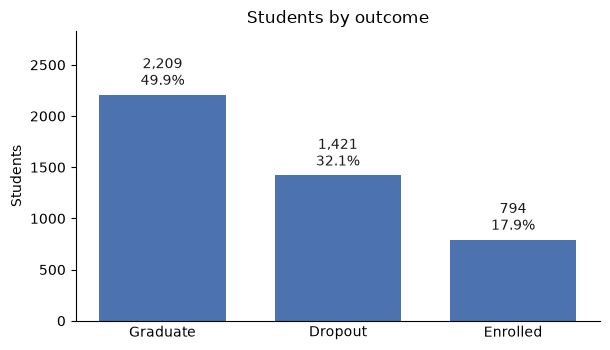

In [17]:
order = ["Graduate", "Dropout", "Enrolled"]
counts = df["Target"].value_counts().reindex(order)
shares = counts / counts.sum() * 100
for name in order:
    print(f"{name}: {int(counts[name])} ({shares[name]:.1f}%)")

fig, ax = plt.subplots(figsize=(6.2, 3.6))
bars = ax.bar(order, counts.to_numpy(), color="#4C72B0", width=0.72)
ax.set_ylabel("Students")
ax.set_xlabel("")
ax.set_title("Students by outcome")
for bar, name in zip(bars, order):
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 50,
        f"{int(height):,}\n{shares[name]:.1f}%",
        ha="center",
        va="bottom",
        fontsize=10,
        color="#1A1A1A",
    )
ax.set_ylim(0, counts.max() * 1.28)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="x", length=0)
fig.tight_layout()
plt.show()


Of the 4,424 students, 2,209 graduated (49.9%), 1,421 dropped out (32.1%), and 794 remained enrolled (17.9%). Macro F1 gives each outcome equal weight despite these differences in class size.

### 4.2 Patterns that inform modelling

**Numeric fields by outcome**

The box plots compare five numeric fields across outcomes for the 4,244 students with recorded semester data.

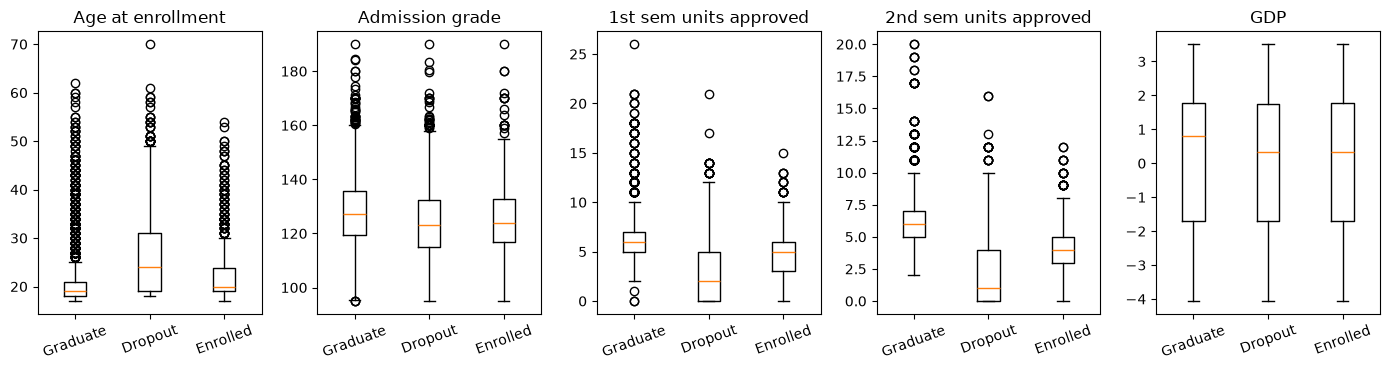

In [18]:
order = ["Graduate", "Dropout", "Enrolled"]
fields = [
    ("Age at enrollment", "Age at enrollment"),
    ("Admission grade", "Admission grade"),
    ("Curricular units 1st sem (approved)", "1st sem units approved"),
    ("Curricular units 2nd sem (approved)", "2nd sem units approved"),
    ("GDP", "GDP"),
]
recorded = df["Curricular units 1st sem (enrolled)"].notna()
plot_df = df.loc[recorded]
fig, axes = plt.subplots(1, len(fields), figsize=(14, 3.8))
for ax, (col, title) in zip(axes, fields):
    groups = [plot_df.loc[plot_df["Target"] == name, col] for name in order]
    ax.boxplot(groups)
    ax.set_xticks([1, 2, 3], order, rotation=20)
    ax.set_title(title)
fig.tight_layout()
plt.show()


Graduates passed a median of six units in each semester, compared with two and one for dropouts and five and four for students still enrolled. Median age at enrolment was 24 for dropouts, 19 for graduates, and 20 for those still enrolled. Admission grade and GDP overlap across outcomes. The first-semester gap motivates comparing enrolment-only models with models that include first-semester results.

**Mean values by outcome**

The following table summarizes selected numeric fields using available values for each field.

In [19]:
summary_cols = [
    "Age at enrollment",
    "Admission grade",
    "Curricular units 1st sem (approved)",
    "Curricular units 2nd sem (approved)",
    "Curricular units 2nd sem (grade)",
]
df.groupby("Target")[summary_cols].mean().round(2)


,Age at enrollment,Admission grade,Curricular units 1st sem (approved),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade)
Target,,,,,
Dropout,26.07,124.96,2.70,2.05,6.24
Enrolled,22.37,125.53,4.48,4.21,11.52
Graduate,21.78,128.79,6.45,6.39,13.14


**Approved units across semesters**

The scatter plot compares approved units in the first and second semesters for the 4,244 students with recorded semester data. The grey diagonal marks equal counts.

correlation: 0.89
equal: 2239 of 4244
first semester higher: 1180
second semester higher: 825


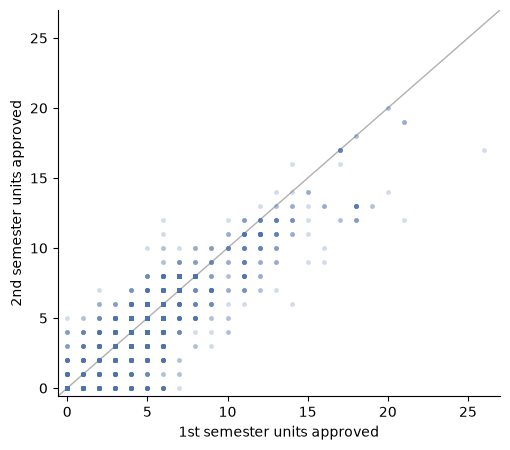

In [20]:
recorded = df["Curricular units 1st sem (enrolled)"].notna()
plot_df = df.loc[recorded]
first = plot_df["Curricular units 1st sem (approved)"]
second = plot_df["Curricular units 2nd sem (approved)"]
print(f"correlation: {first.corr(second):.2f}")
print(f"equal: {int((first == second).sum())} of {len(plot_df)}")
print(f"first semester higher: {int((first > second).sum())}")
print(f"second semester higher: {int((second > first).sum())}")
fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.plot([-0.6, 27], [-0.6, 27], color="#B0B0B0", linewidth=1, zorder=0)
ax.scatter(first, second, s=12, alpha=0.25, color="#4C72B0", linewidths=0)
ax.set_xlim(-0.6, 27)
ax.set_ylim(-0.6, 27)
ax.set_xlabel("1st semester units approved")
ax.set_ylabel("2nd semester units approved")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


The counts are strongly correlated (r = 0.89). They are equal for 2,239 students, higher in the first semester for 1,180, and higher in the second for 825. This motivates evaluating how much second-semester results add beyond the first semester.

**Approved units and semester grades**

The scatter plots compare approved units with average grade for each semester, using the same 4,244 students.

1st sem correlation: 0.65
1st sem correlation, at least one unit approved: 0.26
1st sem approved is 0: 538, and grade is 0 for all of them
2nd sem correlation: 0.73
2nd sem correlation, at least one unit approved: 0.33
2nd sem approved is 0: 690, and grade is 0 for all of them


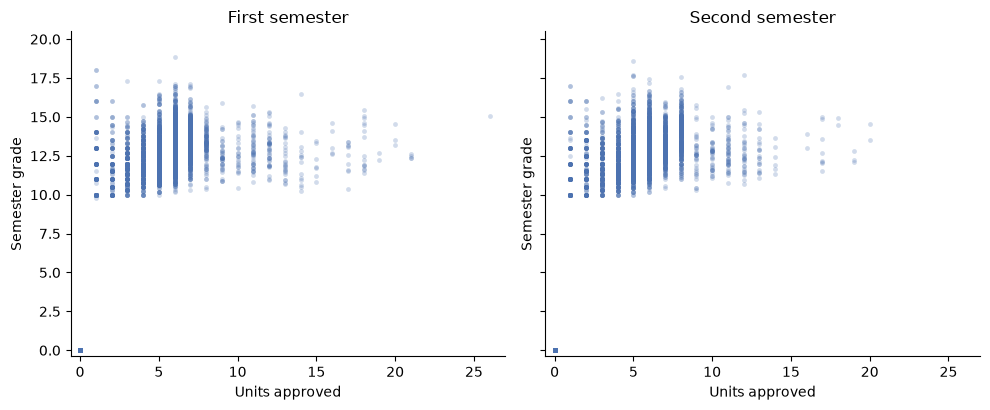

In [21]:
recorded = df["Curricular units 1st sem (enrolled)"].notna()
plot_df = df.loc[recorded]
semesters = [("1st sem", "First semester"), ("2nd sem", "Second semester")]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharex=True, sharey=True)
for ax, (sem, title) in zip(axes, semesters):
    approved = plot_df[f"Curricular units {sem} (approved)"]
    grade = plot_df[f"Curricular units {sem} (grade)"]
    passed = approved > 0
    print(f"{sem} correlation: {approved.corr(grade):.2f}")
    print(f"{sem} correlation, at least one unit approved: {approved[passed].corr(grade[passed]):.2f}")
    print(f"{sem} approved is 0: {int((~passed).sum())}, and grade is 0 for all of them")
    ax.scatter(approved, grade, s=12, alpha=0.25, color="#4C72B0", linewidths=0)
    ax.set_title(title)
    ax.set_xlabel("Units approved")
    ax.set_ylabel("Semester grade")
    ax.set_xlim(-0.6, 27)
    ax.set_ylim(-0.4, 20.5)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


Correlations are 0.65 and 0.73 for the first and second semesters. All 538 and 690 students, respectively, who passed no units received a grade of zero. Among students who passed at least one unit, correlations fall to 0.26 and 0.33, with median grades of 12.6 and 12.7.

**Previous qualification and admission grades**

The scatter plot compares the two grades for all 4,424 students. The diagonal marks equal grades.

correlation: 0.58
equal: 484 of 4424
median admission minus previous: -5.2


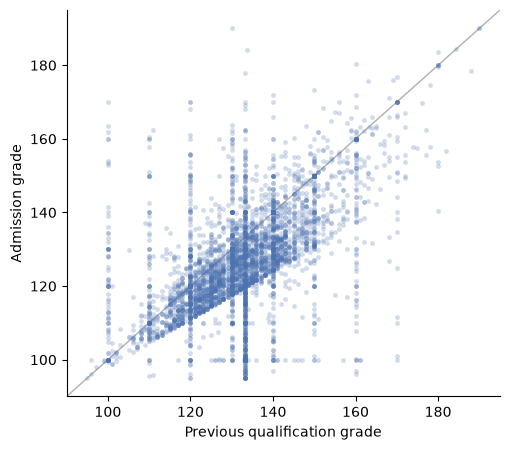

In [22]:
prev = df["Previous qualification (grade)"]
adm = df["Admission grade"]
print(f"correlation: {prev.corr(adm):.2f}")
print(f"equal: {int((prev == adm).sum())} of {len(df)}")
print(f"median admission minus previous: {(adm - prev).median():.1f}")
fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.plot([90, 195], [90, 195], color="#B0B0B0", linewidth=1, zorder=0)
ax.scatter(prev, adm, s=12, alpha=0.25, color="#4C72B0", linewidths=0)
ax.set_xlim(90, 195)
ax.set_ylim(90, 195)
ax.set_xlabel("Previous qualification grade")
ax.set_ylabel("Admission grade")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


The correlation is 0.58; the grades are equal for 484 students. The median difference (admission minus previous qualification grade) is −5.2 points.

### 4.3 Outcome differences and equity

**Outcomes by student group**

The stacked bars show outcome percentages within six binary student groups, with group sizes on the axes.

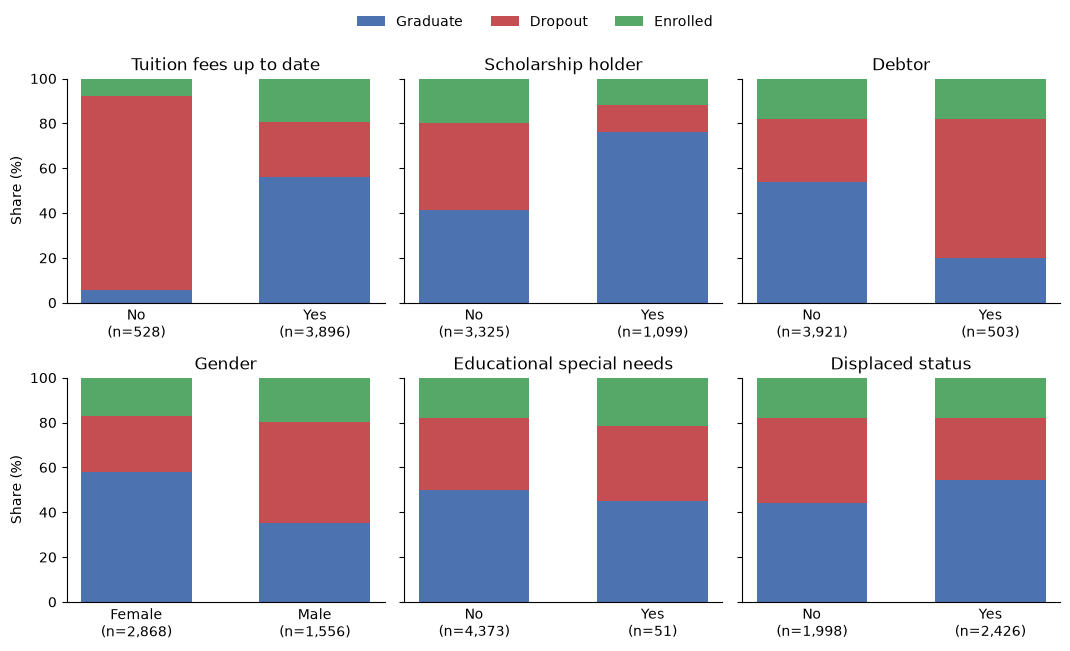

In [23]:
order = ["Graduate", "Dropout", "Enrolled"]
colors = {"Graduate": "#4C72B0", "Dropout": "#C44E52", "Enrolled": "#55A868"}
fields = [
    ("Tuition fees up to date", {0: "No", 1: "Yes"}),
    ("Scholarship holder", {0: "No", 1: "Yes"}),
    ("Debtor", {0: "No", 1: "Yes"}),
    ("Gender", {0: "Female", 1: "Male"}),
    ("Educational special needs", {0: "No", 1: "Yes"}),
    ("Displaced", {0: "No", 1: "Yes"}),
]
fig, axes = plt.subplots(2, 3, figsize=(10.8, 6.6), sharey=True)
for ax, (col, labels) in zip(axes.ravel(), fields):
    counts = pd.crosstab(df[col], df["Target"]).reindex(columns=order)
    shares = counts.div(counts.sum(axis=1), axis=0) * 100
    bottom = None
    x = list(range(len(shares.index)))
    for name in order:
        heights = shares[name].to_numpy()
        ax.bar(
            x,
            heights,
            bottom=0 if bottom is None else bottom,
            color=colors[name],
            width=0.62,
            label=name,
        )
        bottom = heights if bottom is None else bottom + heights
    tick_labels = [
        f"{labels[code]}\n(n={int(counts.loc[code].sum()):,})" for code in shares.index
    ]
    ax.set_xticks(x, tick_labels)
    ax.set_ylim(0, 100)
    ax.set_title("Displaced status" if col == "Displaced" else col)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="x", length=0)
for ax in axes[:, 0]:
    ax.set_ylabel("Share (%)")

handles, legend_labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles,
    legend_labels,
    loc="upper center",
    ncol=3,
    frameon=False,
    bbox_to_anchor=(0.5, 0.99),
)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()


Dropout rates are 86.6% for students whose fees are not up to date versus 24.7% for those whose fees are up to date; 62.0% for debtors versus 28.3% for other students; and 38.7% for students without scholarships versus 12.2% for scholarship holders. These associations motivate the restricted Stage A experiment in Section 6.4.

Dropout rates are 45.1% for male students and 25.1% for female students. Rates are 33.3% for students with recorded educational special needs (17 of 51) versus 32.1% for other students; the smaller group gives a less precise estimate. Rates are 27.6% for displaced students versus 37.6% for non-displaced students.

**Outcomes by course**

Each bar shows outcome percentages within a course, along with its enrolment count.

Target  Graduate  Dropout  Enrolled    n
Course                                  
33           8.3     66.7      25.0   12
9130        29.8     55.3      14.9  141
9119         8.2     54.1      37.6  170
9991        29.1     50.7      20.1  268
9853        29.7     44.3      26.0  192
9003        41.4     41.0      17.6  210
9556        41.9     38.4      19.8   86
171         44.7     38.1      17.2  215
9254        45.6     38.1      16.3  252
9670        46.6     35.4      17.9  268
9147        36.3     35.3      28.4  380
8014        57.2     33.0       9.8  215
9773        59.2     30.5      10.3  331
9085        51.0     26.7      22.3  337
9070        58.8     22.6      18.6  226
9238        69.9     18.3      11.8  355
9500        71.5     15.4      13.1  766


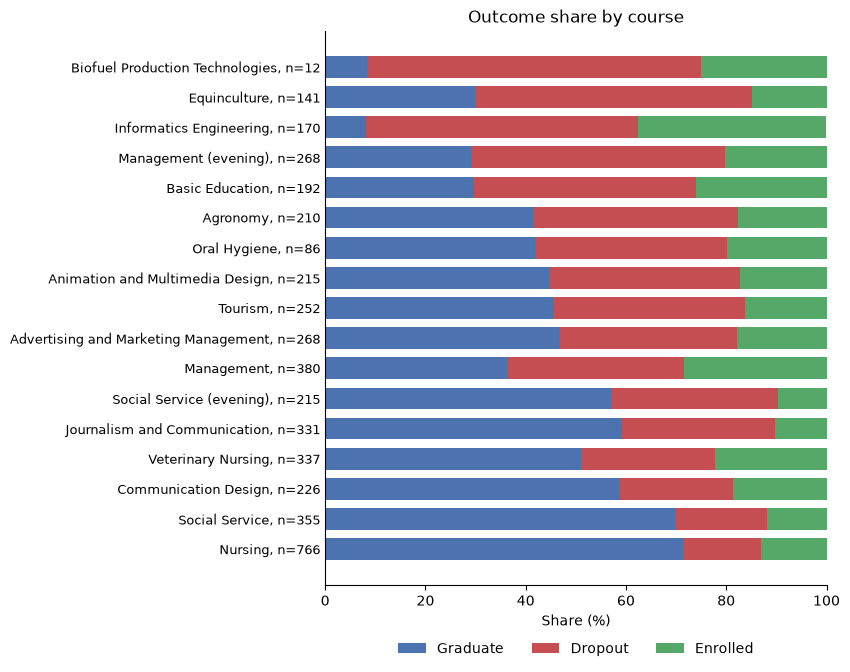

In [24]:
order = ["Graduate", "Dropout", "Enrolled"]
colors = {"Graduate": "#4C72B0", "Dropout": "#C44E52", "Enrolled": "#55A868"}
course_names = {
    33: "Biofuel Production Technologies",
    171: "Animation and Multimedia Design",
    8014: "Social Service (evening)",
    9003: "Agronomy",
    9070: "Communication Design",
    9085: "Veterinary Nursing",
    9119: "Informatics Engineering",
    9130: "Equinculture",
    9147: "Management",
    9238: "Social Service",
    9254: "Tourism",
    9500: "Nursing",
    9556: "Oral Hygiene",
    9670: "Advertising and Marketing Management",
    9773: "Journalism and Communication",
    9853: "Basic Education",
    9991: "Management (evening)",
}
counts = pd.crosstab(df["Course"], df["Target"]).reindex(columns=order)
counts["n"] = counts.sum(axis=1).astype(int)
shares = counts[order].div(counts["n"], axis=0) * 100
shares["n"] = counts["n"]
shares = shares.sort_values("Dropout", ascending=False)
print(shares.round(1).to_string())
fig, ax = plt.subplots(figsize=(8.6, 6.8))
y = list(range(len(shares)))
left = 0
for name in order:
    ax.barh(y, shares[name], left=left, color=colors[name], label=name, height=0.72)
    left = left + shares[name]
ax.set_yticks(
    y,
    [f"{course_names[code]}, n={int(n)}" for code, n in zip(shares.index, shares["n"])],
    fontsize=9,
)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Share (%)")
ax.set_title("Outcome share by course")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.08))
fig.tight_layout()
plt.show()


Among courses with more than 100 students, Equinculture has the highest dropout rate (55.3% of 141 students) and Nursing the lowest (15.4% of 766). In Informatics Engineering, 54.1% of 170 students dropped out and 8.2% graduated. Rates for small courses such as Biofuel Production Technologies (12 students) are sensitive to individual outcomes.

**Gender by course**

The bars compare gender composition across courses.

male: 1556 (35.2%)
Gender  Male  Female    n
Course                   
9119    95.9     4.1  170
33      75.0    25.0   12
9003    71.0    29.0  210
171     54.4    45.6  215
9991    50.7    49.3  268
9670    45.5    54.5  268
9130    44.0    56.0  141
9147    42.6    57.4  380
9070    42.5    57.5  226
9254    39.7    60.3  252
9773    34.7    65.3  331
9556    22.1    77.9   86
8014    19.5    80.5  215
9500    19.5    80.5  766
9085    17.8    82.2  337
9238    13.0    87.0  355
9853     4.7    95.3  192


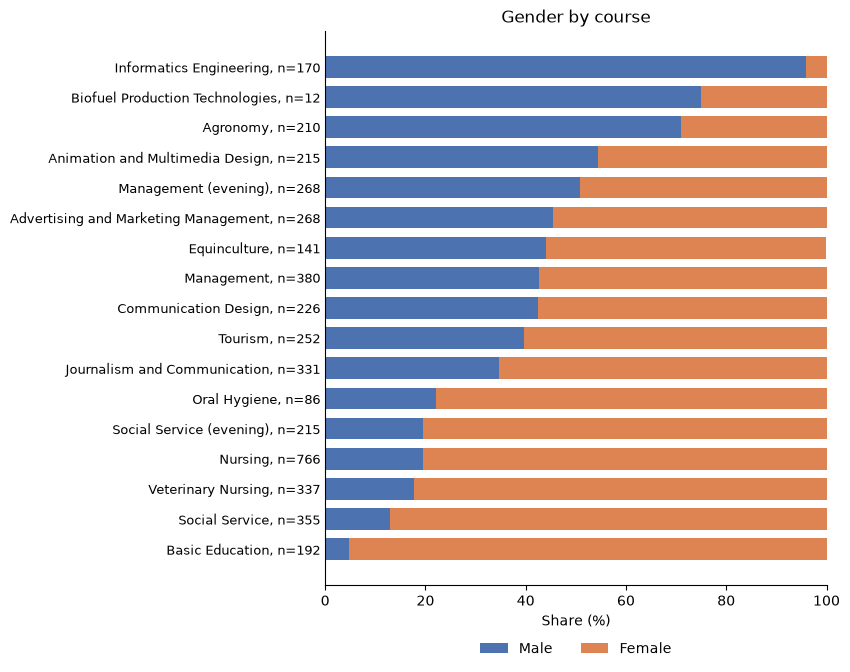

In [25]:
course_names = {
    33: "Biofuel Production Technologies",
    171: "Animation and Multimedia Design",
    8014: "Social Service (evening)",
    9003: "Agronomy",
    9070: "Communication Design",
    9085: "Veterinary Nursing",
    9119: "Informatics Engineering",
    9130: "Equinculture",
    9147: "Management",
    9238: "Social Service",
    9254: "Tourism",
    9500: "Nursing",
    9556: "Oral Hygiene",
    9670: "Advertising and Marketing Management",
    9773: "Journalism and Communication",
    9853: "Basic Education",
    9991: "Management (evening)",
}
levels = [1, 0]
level_names = {1: "Male", 0: "Female"}
colors = {1: "#4C72B0", 0: "#DD8452"}
counts = pd.crosstab(df["Course"], df["Gender"]).reindex(columns=levels)
counts["n"] = counts.sum(axis=1).astype(int)
shares = counts[levels].div(counts["n"], axis=0) * 100
shares["n"] = counts["n"]
shares = shares.sort_values(1, ascending=False)
print(f"male: {int((df['Gender'] == 1).sum())} ({(df['Gender'] == 1).mean() * 100:.1f}%)")
print(shares.rename(columns=level_names).round(1).to_string())
fig, ax = plt.subplots(figsize=(8.6, 6.8))
y = list(range(len(shares)))
left = 0
for code in levels:
    ax.barh(y, shares[code], left=left, color=colors[code], label=level_names[code], height=0.72)
    left = left + shares[code]
ax.set_yticks(
    y,
    [f"{course_names[code]}, n={int(n)}" for code, n in zip(shares.index, shares["n"])],
    fontsize=9,
)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Share (%)")
ax.set_title("Gender by course")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.08))
fig.tight_layout()
plt.show()


Male students make up 35.2% of the dataset. The share is 95.9% in Informatics Engineering, 71.0% in Agronomy, 19.5% in Nursing, 13.0% in Social Service, and 4.7% in Basic Education. Differences in course composition are relevant when interpreting the overall dropout gap by gender.

**Scholarship by course**

The bars compare scholarship status across courses.

scholarship holders: 1099 (24.8%)
Scholarship holder   Yes     No    n
Course                              
9238                38.9   61.1  355
9500                36.3   63.7  766
9773                31.4   68.6  331
9556                31.4   68.6   86
9070                31.0   69.0  226
9254                28.2   71.8  252
9670                25.7   74.3  268
171                 24.2   75.8  215
9853                20.8   79.2  192
9147                20.3   79.7  380
8014                20.0   80.0  215
9085                16.6   83.4  337
9119                11.8   88.2  170
9003                 9.5   90.5  210
9130                 9.2   90.8  141
9991                 7.8   92.2  268
33                   0.0  100.0   12


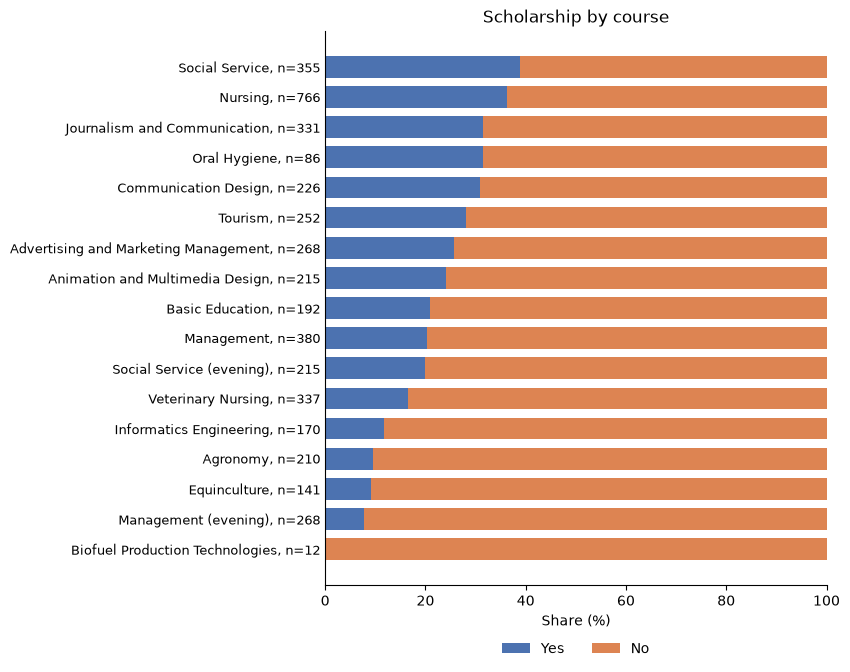

In [26]:
course_names = {
    33: "Biofuel Production Technologies",
    171: "Animation and Multimedia Design",
    8014: "Social Service (evening)",
    9003: "Agronomy",
    9070: "Communication Design",
    9085: "Veterinary Nursing",
    9119: "Informatics Engineering",
    9130: "Equinculture",
    9147: "Management",
    9238: "Social Service",
    9254: "Tourism",
    9500: "Nursing",
    9556: "Oral Hygiene",
    9670: "Advertising and Marketing Management",
    9773: "Journalism and Communication",
    9853: "Basic Education",
    9991: "Management (evening)",
}
levels = [1, 0]
level_names = {1: "Yes", 0: "No"}
colors = {1: "#4C72B0", 0: "#DD8452"}
counts = pd.crosstab(df["Course"], df["Scholarship holder"]).reindex(columns=levels)
counts["n"] = counts.sum(axis=1).astype(int)
shares = counts[levels].div(counts["n"], axis=0) * 100
shares["n"] = counts["n"]
shares = shares.sort_values(1, ascending=False)
holders = int((df["Scholarship holder"] == 1).sum())
print(f"scholarship holders: {holders} ({holders / len(df) * 100:.1f}%)")
print(shares.rename(columns=level_names).round(1).to_string())
fig, ax = plt.subplots(figsize=(8.6, 6.8))
y = list(range(len(shares)))
left = 0
for code in levels:
    ax.barh(y, shares[code], left=left, color=colors[code], label=level_names[code], height=0.72)
    left = left + shares[code]
ax.set_yticks(
    y,
    [f"{course_names[code]}, n={int(n)}" for code, n in zip(shares.index, shares["n"])],
    fontsize=9,
)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Share (%)")
ax.set_title("Scholarship by course")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.08))
fig.tight_layout()
plt.show()


Scholarship holders make up 24.8% of students. The share is 38.9% in Social Service and 36.3% in Nursing, compared with 7.8% in evening Management, 9.2% in Equinculture, and 9.5% in Agronomy. Small course sizes should be considered when interpreting these percentages.

### 4.4 Additional exploratory analysis

**Parents’ qualifications**

The heatmap shows the distribution of fathers’ qualifications within mothers’ qualification categories, restricted to codes with at least 50 observations for each parent.

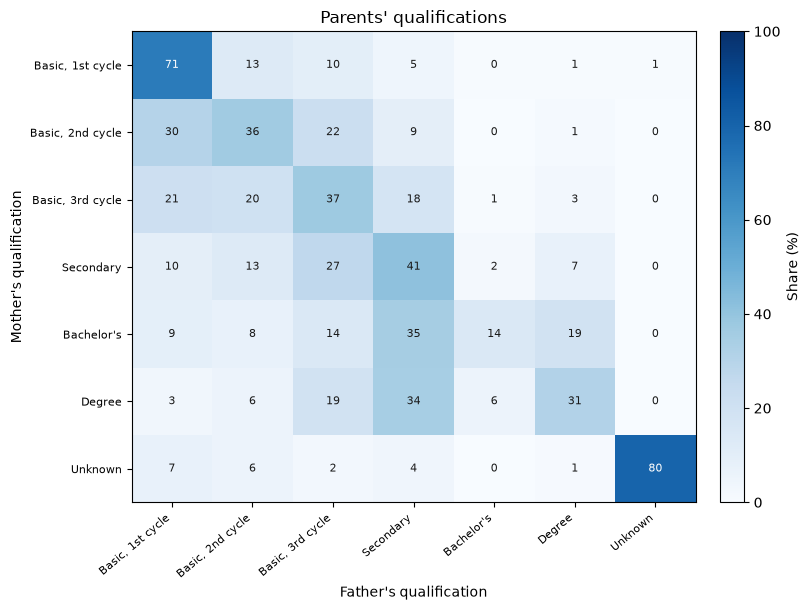

In [27]:
order = [37, 38, 19, 1, 2, 3, 34]
labels = {
    37: "Basic, 1st cycle",
    38: "Basic, 2nd cycle",
    19: "Basic, 3rd cycle",
    1: "Secondary",
    2: "Bachelor's",
    3: "Degree",
    34: "Unknown",
}
mother = "Mother's qualification"
father = "Father's qualification"
keep = [code for code in order if (df[mother] == code).sum() >= 50 and (df[father] == code).sum() >= 50]
sub = df[df[mother].isin(keep) & df[father].isin(keep)]
shares = pd.crosstab(sub[mother], sub[father], normalize="index").reindex(index=keep, columns=keep) * 100
same = int((sub[mother] == sub[father]).sum())
fig, ax = plt.subplots(figsize=(8.2, 6.2))
image = ax.imshow(shares.to_numpy(), cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(keep)), [labels[code] for code in keep], rotation=40, ha="right", fontsize=8)
ax.set_yticks(range(len(keep)), [labels[code] for code in keep], fontsize=8)
ax.set_xlabel("Father's qualification")
ax.set_ylabel("Mother's qualification")
ax.set_title("Parents' qualifications")
for i in range(len(keep)):
    for j in range(len(keep)):
        value = shares.iloc[i, j]
        ax.text(
            j,
            i,
            f"{value:.0f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if value >= 55 else "#1A1A1A",
        )
fig.colorbar(image, ax=ax, label="Share (%)", fraction=0.046, pad=0.04)
fig.tight_layout()
plt.show()


Among the 4,131 students included, 1,919 (46.5%) have parents with the same qualification code. The strongest matches are basic education, first cycle (71%), and unknown (80%).

**Parents’ occupations**

The heatmap uses the same conditional-share approach for occupation codes with at least 50 observations for the corresponding parent.

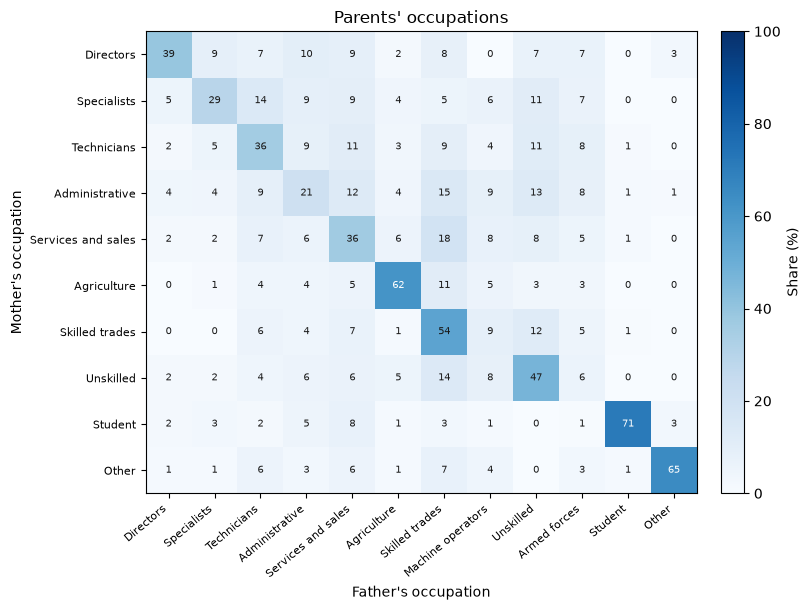

In [28]:
order = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 0, 90]
labels = {
    0: "Student",
    1: "Directors",
    2: "Specialists",
    3: "Technicians",
    4: "Administrative",
    5: "Services and sales",
    6: "Agriculture",
    7: "Skilled trades",
    8: "Machine operators",
    9: "Unskilled",
    10: "Armed forces",
    90: "Other",
}
mother = "Mother's occupation"
father = "Father's occupation"
keep_mother = [code for code in order if (df[mother] == code).sum() >= 50]
keep_father = [code for code in order if (df[father] == code).sum() >= 50]
sub = df[df[mother].isin(keep_mother) & df[father].isin(keep_father)]
shares = (
    pd.crosstab(sub[mother], sub[father], normalize="index")
    .reindex(index=keep_mother, columns=keep_father)
    * 100
)
same = int((sub[mother] == sub[father]).sum())
fig, ax = plt.subplots(figsize=(8.2, 6.2))
image = ax.imshow(shares.to_numpy(), cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(
    range(len(keep_father)),
    [labels[code] for code in keep_father],
    rotation=40,
    ha="right",
    fontsize=8,
)
ax.set_yticks(range(len(keep_mother)), [labels[code] for code in keep_mother], fontsize=8)
ax.set_xlabel("Father's occupation")
ax.set_ylabel("Mother's occupation")
ax.set_title("Parents' occupations")
for i in range(len(keep_mother)):
    for j in range(len(keep_father)):
        value = shares.iloc[i, j]
        ax.text(
            j,
            i,
            f"{value:.0f}",
            ha="center",
            va="center",
            fontsize=7,
            color="white" if value >= 55 else "#1A1A1A",
        )
fig.colorbar(image, ax=ax, label="Share (%)", fraction=0.046, pad=0.04)
fig.tight_layout()
plt.show()


Among the 4,268 students included, 1,711 (40.1%) have parents with the same occupation code. The strongest matches are students (71%), agriculture (62%), other (65%), and skilled trades (54%).

**Age at enrolment**

The histogram shows the overall age distribution without separating outcomes.

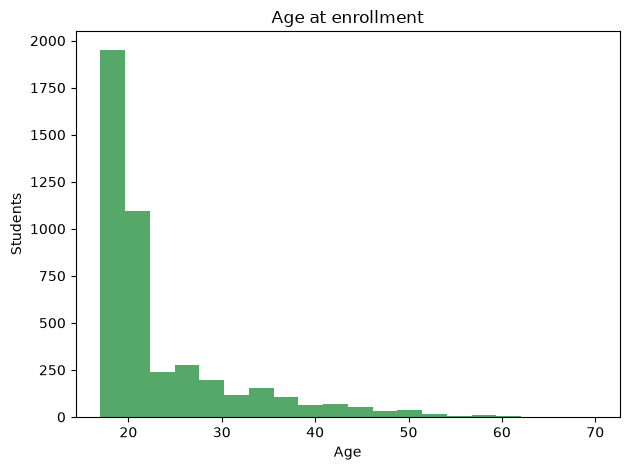

In [29]:
df["Age at enrollment"].plot(kind="hist", bins=20, color="#55A868")
plt.title("Age at enrollment")
plt.xlabel("Age")
plt.ylabel("Students")
plt.tight_layout()
plt.show()


## 5. Feature engineering

We derive new features, prepare categorical and numerical inputs, and define cumulative feature sets for the three prediction stages. Features derived from individual student records can be constructed before splitting; preprocessing parameters are fitted using training data only.

### 5.1 New fields from the curricular units

| New field | Built from |
|---|---|
| `Curricular units missing` | 1 for the 180 course 171 rows whose twelve curricular fields are missing, 0 otherwise |
| `Pass rate 1st sem` | 1st sem approved ÷ 1st sem enrolled |
| `Pass rate 2nd sem` | 2nd sem approved ÷ 2nd sem enrolled |
| `Pass rate overall` | approved units from both semesters ÷ enrolled units from both semesters |

Pass rates account for differences in the number of units taken. Students who pass 5 of 5 and 5 of 10 units have the same approved count but pass rates of 1.0 and 0.5, respectively.

All three pass rates are missing for the 180 affected students and range from 0 to 1 for the remaining students. The missing-data indicator identifies these records using first-semester enrolment, and all original curricular-unit fields are retained.

In [30]:
def add_features(frame):
    """Return a copy of frame with the fields from 5.1 added. Uses each row on its own."""
    out = frame.copy()
    first_enrolled = out["Curricular units 1st sem (enrolled)"]
    second_enrolled = out["Curricular units 2nd sem (enrolled)"]
    first_approved = out["Curricular units 1st sem (approved)"]
    second_approved = out["Curricular units 2nd sem (approved)"]

    out["Curricular units missing"] = first_enrolled.isna().astype(int)
    out["Pass rate 1st sem"] = first_approved / first_enrolled
    out["Pass rate 2nd sem"] = second_approved / second_enrolled
    out["Pass rate overall"] = (first_approved + second_approved) / (first_enrolled + second_enrolled)
    return out


NEW_FIELDS = [
    "Curricular units missing",
    "Pass rate 1st sem",
    "Pass rate 2nd sem",
    "Pass rate overall",
]

data = add_features(df)
assert data["Curricular units missing"].sum() == 180
rates = ["Pass rate 1st sem", "Pass rate 2nd sem", "Pass rate overall"]
assert not np.isinf(data[rates].to_numpy(dtype=float)).any()
assert data[rates].min().min() >= 0 and data[rates].max().max() <= 1

print("rows flagged missing:", int(data["Curricular units missing"].sum()))
print("missing cells per new field:")
print(data[NEW_FIELDS].isna().sum().to_string())
print()
print("median by outcome (180 missing rows left out):")
data.groupby("Target")[NEW_FIELDS[1:]].median().round(2)

rows flagged missing: 180
missing cells per new field:
Curricular units missing      0
Pass rate 1st sem           180
Pass rate 2nd sem           180
Pass rate overall           180

median by outcome (180 missing rows left out):


,Pass rate 1st sem,Pass rate 2nd sem,Pass rate overall
Target,,,
Dropout,0.4,0.17,0.30
Enrolled,0.8,0.71,0.75
Graduate,1.0,1.00,1.00


Median pass rates for graduates are 1.0 in both semesters, compared with 0.80 and 0.71 for enrolled students and 0.40 and 0.17 for dropouts. Students who dropped out had a median overall pass rate of 0.30.

### 5.2 Coding and standardizing

#### Coding

| Field | Coding |
|---|---|
| `Marital status` | one-hot |
| `Application mode` | one-hot |
| `Course` | one-hot |
| `Daytime/evening attendance` | already 0/1 |
| `Previous qualification` | one-hot |
| `Nacionality` | one-hot |
| `Mother's qualification` | one-hot |
| `Father's qualification` | one-hot |
| `Mother's occupation` | one-hot |
| `Father's occupation` | one-hot |
| `Displaced` | already 0/1 |
| `Educational special needs` | already 0/1 |
| `Debtor` | already 0/1 |
| `Tuition fees up to date` | already 0/1 |
| `Gender` | already 0/1 |
| `Scholarship holder` | already 0/1 |
| `International` | already 0/1 |
| `Target` | label, not an input |
| `Curricular units missing` | already 0/1 |

Categorical codes identify categories rather than quantities: course 171 represents Animation and Multimedia Design, while 9500 represents Nursing. One-hot encoding avoids imposing a numerical ordering. Categories occurring fewer than 20 times in the training data are grouped into an infrequent category; unseen categories are assigned there when it exists. Binary fields remain unchanged.

#### Numerical preprocessing

| Configuration | Missing values | Standardization |
|---|---|---|
| Median fill | Training median | Yes |
| Keep missing | Retained | No |

Standardization subtracts the training mean and divides by the training standard deviation. Median imputation allows models that cannot handle missing values to retain all records. Zero imputation is avoided because zero is a meaningful curricular-unit value, not a suitable replacement for missing records. The missing-data indicator remains binary in both configurations.

In [31]:
ONE_HOT = [
    "Marital status",
    "Application mode",
    "Course",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
]
AS_RECORDED = [
    "Daytime/evening attendance",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International",
    "Curricular units missing",
]
MIN_CODE_COUNT = 20

TO_STANDARDIZE = [col for col in data.columns if col not in ONE_HOT + AS_RECORDED + ["Target"]]
assert set(ONE_HOT + AS_RECORDED + TO_STANDARDIZE + ["Target"]) == set(data.columns)
for col in ONE_HOT:
    counts = data[col].value_counts()
    print(f"{col}: {len(counts)} codes, {int((counts >= MIN_CODE_COUNT).sum())} with {MIN_CODE_COUNT}+ students")

Marital status: 6 codes, 4 with 20+ students
Application mode: 18 codes, 12 with 20+ students
Course: 17 codes, 16 with 20+ students
Previous qualification: 17 codes, 8 with 20+ students
Nacionality: 21 codes, 2 with 20+ students
Mother's qualification: 29 codes, 10 with 20+ students
Father's qualification: 34 codes, 10 with 20+ students
Mother's occupation: 32 codes, 12 with 20+ students
Father's occupation: 46 codes, 12 with 20+ students


### 5.3 Feature sets by stage

We construct four feature sets across three prediction stages to assess how early academic outcomes can be predicted.

| Set | Prediction stage | Included features | Count |
|---|---|---|---:|
| A (restricted) | At enrolment | A (full) excluding the three financial fields listed below | 21 |
| A (full) | At enrolment | Demographics, application and admission, family background, socioeconomic factors, and macroeconomic indicators | 24 |
| B | After semester one | A (full) + six first-semester fields, first-semester pass rate, and missing curricular data indicator | 32 |
| C | After semester two | B + six second-semester fields, second-semester pass rate, and overall pass rate | 40 |

Feature counts are before one-hot encoding. Both models are fitted using each feature set and the same train/test split.

The recording time of `Tuition fees up to date`, `Debtor`, and `Scholarship holder` is uncertain. Stage A (restricted) excludes these fields to assess enrolment-time prediction without potentially later information.

In [32]:
FIRST_SEM = [col for col in data.columns if col.startswith("Curricular units 1st sem")]
SECOND_SEM = [col for col in data.columns if col.startswith("Curricular units 2nd sem")]

STAGE_A = [
    col
    for col in data.columns
    if col not in FIRST_SEM + SECOND_SEM + NEW_FIELDS + ["Target"]
]
STAGE_B = STAGE_A + FIRST_SEM + ["Pass rate 1st sem", "Curricular units missing"]
STAGE_C = STAGE_B + SECOND_SEM + ["Pass rate 2nd sem", "Pass rate overall"]
STAGES = {"A": STAGE_A, "B": STAGE_B, "C": STAGE_C}

MONEY_FIELDS = ["Tuition fees up to date", "Debtor", "Scholarship holder"]
FEATURE_SETS = {
    "A (restricted)": [col for col in STAGE_A if col not in MONEY_FIELDS],
    "A (full)": STAGE_A,
    "B": STAGE_B,
    "C": STAGE_C,
}

assert len(STAGE_C) == len(set(STAGE_C)) == data.shape[1] - 1
for name, cols in FEATURE_SETS.items():
    print(f"{name}: {len(cols)} fields")


def make_preprocessor(columns, fill_missing=True):
    """Code the category fields.

    fill_missing=True fills numeric gaps with the training median, then
    standardizes. fill_missing=False keeps the recorded values and the
    missing entries. Fit on the training rows only.
    """
    one_hot = [col for col in columns if col in ONE_HOT]
    as_recorded = [col for col in columns if col in AS_RECORDED]
    to_standardize = [col for col in columns if col in TO_STANDARDIZE]
    if fill_missing:
        numeric_steps = Pipeline(
            [
                ("fill", SimpleImputer(strategy="median")),
                ("standardize", StandardScaler()),
            ]
        )
    else:
        numeric_steps = "passthrough"
    encode = OneHotEncoder(
        min_frequency=MIN_CODE_COUNT,
        handle_unknown="infrequent_if_exist",
        sparse_output=False,
    )
    return ColumnTransformer(
        [
            ("one_hot", encode, one_hot),
            ("standardize", numeric_steps, to_standardize),
            ("as_recorded", "passthrough", as_recorded),
        ]
    )

A (restricted): 21 fields
A (full): 24 fields
B: 32 fields
C: 40 fields


### 5.4 Train/test split

We reserve 20% of students for testing using a stratified split to preserve the outcome distribution. All models use the same split. Preprocessing parameters are fitted using training data only, including within cross-validation folds during hyperparameter tuning.

The following checks verify that median imputation removes missing values and that the keep-missing configuration preserves them.

In [33]:
X = data.drop(columns="Target")
y = data["Target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)
print(f"train rows: {len(X_train)}, test rows: {len(X_test)}")
print("train shares:", (y_train.value_counts(normalize=True) * 100).round(1).to_dict())
print("test shares: ", (y_test.value_counts(normalize=True) * 100).round(1).to_dict())
print()

for name, cols in FEATURE_SETS.items():
    for fill_missing, label in ((True, "median fill"), (False, "keep missing")):
        prep = make_preprocessor(cols, fill_missing=fill_missing).fit(X_train[cols])
        train_out = prep.transform(X_train[cols])
        test_out = prep.transform(X_test[cols])
        missing_rows = int(
            np.isnan(train_out).any(axis=1).sum() + np.isnan(test_out).any(axis=1).sum()
        )
        if fill_missing or name in ("A (restricted)", "A (full)"):
            assert missing_rows == 0
        else:
            assert missing_rows == 180
        print(
            f"{name}, {label}: {len(cols)} fields -> {train_out.shape[1]} model inputs, "
            f"rows with a missing value: {missing_rows}"
        )

train rows: 3539, test rows: 885
train shares: {'Graduate': 49.9, 'Dropout': 32.1, 'Enrolled': 17.9}
test shares:  {'Graduate': 49.9, 'Dropout': 32.1, 'Enrolled': 18.0}

A (restricted), median fill: 21 fields -> 104 model inputs, rows with a missing value: 0
A (restricted), keep missing: 21 fields -> 104 model inputs, rows with a missing value: 0
A (full), median fill: 24 fields -> 107 model inputs, rows with a missing value: 0
A (full), keep missing: 24 fields -> 107 model inputs, rows with a missing value: 0
B, median fill: 32 fields -> 115 model inputs, rows with a missing value: 0
B, keep missing: 32 fields -> 115 model inputs, rows with a missing value: 180
C, median fill: 40 fields -> 123 model inputs, rows with a missing value: 0
C, keep missing: 40 fields -> 123 model inputs, rows with a missing value: 180


## 6. Modelling

We compare logistic regression and random forest against a majority-class baseline. Hyperparameters are selected using 5-fold stratified cross-validation on the training set, scored by macro F1. All models use the train/test split established in Section 5.4. Sections 6.2 and 6.3 demonstrate each model using Stage C before the comparison across stages.

### 6.1 Baseline

The baseline uses a `DummyClassifier` with the `most_frequent` strategy, predicting the most common training outcome (Graduate) for every student. It provides a reference point for evaluating the other models.

In [34]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_predicted = baseline.predict(X_train)
print(f"most common training outcome: {y_train.value_counts().idxmax()}")
print(f"train macro F1: {f1_score(y_train, baseline_predicted, average='macro'):.3f}")

most common training outcome: Graduate
train macro F1: 0.222


### 6.2 Logistic regression

Multinomial logistic regression provides an interpretable linear classification model against which a more complex, nonlinear model can be compared. We use the median-filled, standardized preprocessing configuration from Section 5.2.

#### Cross-validation

We tune `C`, the inverse of regularization strength, over 0.01, 0.1, 1, 10, and 100. Smaller values impose stronger regularization. When cross-validation scores tie to three decimal places, we select the smaller `C`.

In [35]:
from IPython.display import display

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)


def choose_logistic_C(cv_results, best_score):
    # Smallest C among values tied for the best CV score at three decimals.
    best_rounded = round(float(best_score), 3)
    tied = sorted(
        {
            float(c)
            for c, score in zip(cv_results["param_classify__C"], cv_results["mean_test_score"])
            if round(float(score), 3) == best_rounded
        }
    )
    return tied[0], tied


search = GridSearchCV(
    Pipeline(
        [
            ("prep", make_preprocessor(STAGE_C)),
            ("classify", LogisticRegression(max_iter=2000, random_state=RANDOM_SEED)),
        ]
    ),
    param_grid={"classify__C": [0.01, 0.1, 1, 10, 100]},
    scoring="f1_macro",
    cv=cv,
)
search.fit(X_train[STAGE_C], y_train)
chosen_C, tied_Cs = choose_logistic_C(search.cv_results_, search.best_score_)
model = Pipeline(
    [
        ("prep", make_preprocessor(STAGE_C)),
        ("classify", LogisticRegression(C=chosen_C, max_iter=2000, random_state=RANDOM_SEED)),
    ]
).fit(X_train[STAGE_C], y_train)

results = pd.DataFrame(search.cv_results_)[
    ["param_classify__C", "mean_test_score"]
].rename(
    columns={
        "param_classify__C": "C",
        "mean_test_score": "mean 5-fold macro F1",
    }
)
results["C"] = results["C"].astype(float)
results["mean 5-fold macro F1"] = results["mean 5-fold macro F1"].astype(float).round(3)
display(results)
print(f"chosen C: {int(chosen_C) if float(chosen_C).is_integer() else chosen_C}")
if len(tied_Cs) > 1:
    print(f"tied at best CV score: {tied_Cs}; kept the smallest C")

,C,mean 5-fold macro F1
0,0.01,0.658
1,0.10,0.701
2,1.00,0.706
3,10.00,0.710
4,100.00,0.710


chosen C: 10
tied at best CV score: [10.0, 100.0]; kept the smallest C


### 6.3 Random forest

Random forest captures nonlinear relationships and feature interactions. Feature importance scores help identify informative risk indicators at different stages and guide investigation into potential areas for student support. Predictive importance does not establish causality. We use the keep-missing preprocessing configuration from Section 5.2.

#### Cross-validation

| Hyperparameter | Candidate values |
|---|---|
| Number of trees | 100, 300, 500 |
| Maximum tree depth | 10, 20, unrestricted |

In [36]:
forest_search = GridSearchCV(
    Pipeline(
        [
            ("prep", make_preprocessor(STAGE_C, fill_missing=False)),
            ("classify", RandomForestClassifier(random_state=RANDOM_SEED)),
        ]
    ),
    param_grid={
        "classify__n_estimators": [100, 300, 500],
        "classify__max_depth": [None, 10, 20],
    },
    scoring="f1_macro",
    cv=cv,
)
forest_search.fit(X_train[STAGE_C], y_train)
forest_model = forest_search.best_estimator_

results = pd.DataFrame(forest_search.cv_results_)[
    ["param_classify__n_estimators", "param_classify__max_depth", "mean_test_score"]
].rename(
    columns={
        "param_classify__n_estimators": "n_estimators",
        "param_classify__max_depth": "max_depth",
        "mean_test_score": "mean 5-fold macro F1",
    }
)
display(results)
print(f"chosen n_estimators: {forest_search.best_params_['classify__n_estimators']}")
print(f"chosen max_depth: {forest_search.best_params_['classify__max_depth']}")

,n_estimators,max_depth,mean 5-fold macro F1
0,100,None,0.687443
1,300,None,0.690950
2,500,None,0.690186
3,100,10,0.683739
4,300,10,0.679926
5,500,10,0.680045
6,100,20,0.694962
7,300,20,0.693150
8,500,20,0.698489


chosen n_estimators: 500
chosen max_depth: 20


### 6.4 Modelling across stages

Both models are tuned separately for each of the four feature sets defined in Section 5.3 to investigate how predictive performance changes as additional information becomes available.

#### Cross-validation

The table reports the selected hyperparameters and cross-validation scores for each model and feature set.

In [37]:
from IPython.display import display

MODELS = {
    "Logistic regression": (
        LogisticRegression(max_iter=2000, random_state=RANDOM_SEED),
        {"classify__C": [0.01, 0.1, 1, 10, 100]},
        True,
    ),
    "Random forest": (
        RandomForestClassifier(random_state=RANDOM_SEED, n_jobs=-1),
        {"classify__n_estimators": [100, 300, 500], "classify__max_depth": [None, 10, 20]},
        False,
    ),
}

stage_choices = {}
cv_rows = []
for model_name, (estimator, grid, fill_missing) in MODELS.items():
    for set_name, cols in FEATURE_SETS.items():
        search = GridSearchCV(
            Pipeline(
                [
                    ("prep", make_preprocessor(cols, fill_missing=fill_missing)),
                    ("classify", estimator),
                ]
            ),
            param_grid=grid,
            scoring="f1_macro",
            cv=cv,
        )
        search.fit(X_train[cols], y_train)
        if model_name == "Logistic regression":
            chosen_C, _ = choose_logistic_C(search.cv_results_, search.best_score_)
            params = {"C": chosen_C}
            settings = f"C={int(chosen_C) if float(chosen_C).is_integer() else chosen_C}"
        else:
            params = {
                key.removeprefix("classify__"): value
                for key, value in search.best_params_.items()
            }
            settings = ", ".join(f"{key}={value}" for key, value in params.items())
        stage_choices[(model_name, set_name)] = {
            "cols": cols,
            "fill_missing": fill_missing,
            "params": params,
            "settings": settings,
            "cv_score": search.best_score_,
        }
        cv_rows.append(
            {
                "model": model_name,
                "features": set_name,
                "fields": len(cols),
                "settings": settings,
                "CV macro F1": search.best_score_,
            }
        )

stage_cv = pd.DataFrame(cv_rows)
display(stage_cv.round(3))


,model,features,fields,settings,CV macro F1
0,Logistic regression,A (restricted),21,C=10,0.498
1,Logistic regression,A (full),24,C=100,0.555
2,Logistic regression,B,32,C=10,0.671
3,Logistic regression,C,40,C=10,0.710
4,Random forest,A (restricted),21,"max_depth=None, n_estimators=100",0.480
5,Random forest,A (full),24,"max_depth=None, n_estimators=500",0.530
6,Random forest,B,32,"max_depth=None, n_estimators=300",0.663
7,Random forest,C,40,"max_depth=20, n_estimators=500",0.698


#### Fitting

Each model is fitted on the full training set using its selected hyperparameters. The fitted models are retained for evaluation in Section 7.

In [38]:
def test_scores(y_true, y_pred):
    precision, recall, _, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=["Dropout"], zero_division=0
    )
    return {
        "test macro F1": f1_score(y_true, y_pred, average="macro"),
        "dropout recall": recall[0],
        "dropout precision": precision[0],
        "accuracy": accuracy_score(y_true, y_pred),
    }


rows = [
    {
        "model": "Baseline (always Graduate)",
        "features": "any",
        "fields": "-",
        "settings": "-",
        "CV macro F1": np.nan,
        **test_scores(y_test, baseline.predict(X_test)),
    }
]
stage_models = {}
for model_name in MODELS:
    for set_name, cols in FEATURE_SETS.items():
        choice = stage_choices[(model_name, set_name)]
        params = choice["params"]
        if model_name == "Logistic regression":
            fitted = Pipeline(
                [
                    ("prep", make_preprocessor(cols, fill_missing=True)),
                    (
                        "classify",
                        LogisticRegression(
                            C=params["C"], max_iter=2000, random_state=RANDOM_SEED
                        ),
                    ),
                ]
            ).fit(X_train[cols], y_train)
        else:
            fitted = Pipeline(
                [
                    ("prep", make_preprocessor(cols, fill_missing=False)),
                    (
                        "classify",
                        RandomForestClassifier(
                            n_estimators=params["n_estimators"],
                            max_depth=params["max_depth"],
                            random_state=RANDOM_SEED,
                            n_jobs=-1,
                        ),
                    ),
                ]
            ).fit(X_train[cols], y_train)
        stage_models[(model_name, set_name)] = fitted
        rows.append(
            {
                "model": model_name,
                "features": set_name,
                "fields": len(cols),
                "settings": choice["settings"],
                "CV macro F1": choice["cv_score"],
                **test_scores(y_test, fitted.predict(X_test[cols])),
            }
        )

stage_results = pd.DataFrame(rows)
print(f"fitted models: {len(stage_models)}")
print(f"feature sets: {list(FEATURE_SETS)}")


fitted models: 8
feature sets: ['A (restricted)', 'A (full)', 'B', 'C']


## 7. Evaluation

We compare the models across feature sets on the held-out test set. We examine class-level errors, ROC curves, training-set size, sensitivity to misclassification costs, and differences across student groups. A paired bootstrap estimates uncertainty in differences between test scores.


### 7.1 Comparison across stages

Section 6.4 fitted the logistic regression and the random forest on each feature set. The table below scores those fits on the test rows, using the same baseline as in section 6.1. It reports macro F1 and dropout recall from the proposal, along with dropout precision and accuracy. Dropout recall is the share of students who dropped out that the model flags. Dropout precision is the share of flagged students who did drop out, so a low value means many false alarms.


In [39]:
from IPython.display import display

display(stage_results.round(3))


,model,features,fields,settings,CV macro F1,test macro F1,dropout recall,dropout precision,accuracy
0,Baseline (always Graduate),any,-,-,NaN,0.222,0.000,0.000,0.499
1,Logistic regression,A (restricted),21,C=10,0.498,0.468,0.496,0.560,0.581
2,Logistic regression,A (full),24,C=100,0.555,0.521,0.588,0.668,0.627
3,Logistic regression,B,32,C=10,0.671,0.672,0.739,0.781,0.747
4,Logistic regression,C,40,C=10,0.710,0.700,0.768,0.790,0.773
5,Random forest,A (restricted),21,"max_depth=None, n_estimators=100",0.480,0.470,0.525,0.569,0.585
6,Random forest,A (full),24,"max_depth=None, n_estimators=500",0.530,0.515,0.606,0.630,0.638
7,Random forest,B,32,"max_depth=None, n_estimators=300",0.663,0.641,0.746,0.754,0.747
8,Random forest,C,40,"max_depth=20, n_estimators=500",0.698,0.716,0.782,0.819,0.792


The next cell plots the two proposal measures from the table—macro F1 and dropout recall—for A (restricted), A (full), B, and C. The dashed line is the baseline, which never flags a dropout.


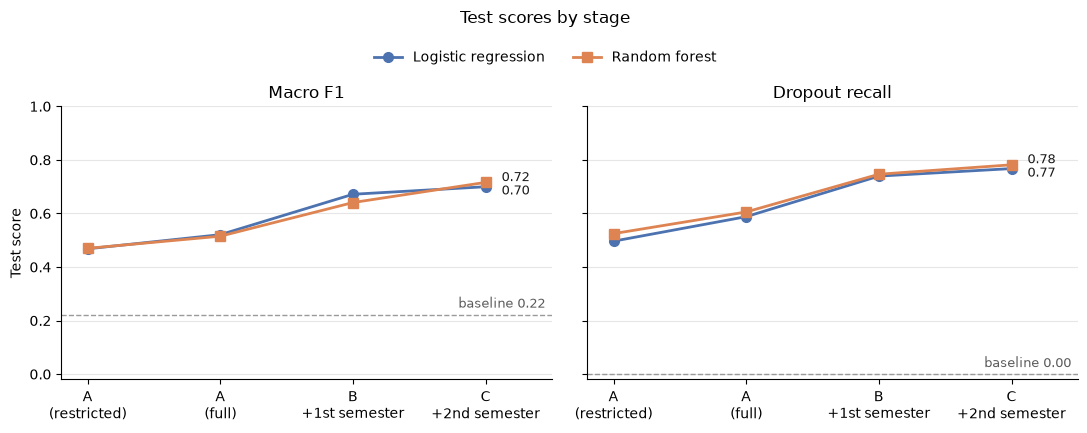

In [40]:
stage_order = ["A (restricted)", "A (full)", "B", "C"]
stage_ticks = [
    "A\n(restricted)",
    "A\n(full)",
    "B\n+1st semester",
    "C\n+2nd semester",
]
model_styles = {
    "Logistic regression": ("#4C72B0", "o"),
    "Random forest": ("#DD8452", "s"),
}
measures = [("test macro F1", "Macro F1"), ("dropout recall", "Dropout recall")]
baseline_row = stage_results.iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (column, title) in zip(axes, measures):
    ax.axhline(baseline_row[column], color="#9A9A9A", linewidth=1, linestyle="--")
    ax.text(
        3.45,
        baseline_row[column] + 0.015,
        f"baseline {baseline_row[column]:.2f}",
        color="#5A5A5A",
        fontsize=9,
        va="bottom",
        ha="right",
    )
    end_labels = []
    for model_name, (color, marker) in model_styles.items():
        values = (
            stage_results[stage_results["model"] == model_name]
            .set_index("features")
            .loc[stage_order, column]
        )
        ax.plot(
            range(len(stage_order)),
            values.to_numpy(),
            color=color,
            marker=marker,
            linewidth=2,
            markersize=7,
            label=model_name,
        )
        end_labels.append([values.iloc[-1], f"{values.iloc[-1]:.2f}"])
    end_labels.sort()
    if end_labels[1][0] - end_labels[0][0] < 0.05:
        middle = (end_labels[0][0] + end_labels[1][0]) / 2
        end_labels[0][0], end_labels[1][0] = middle - 0.025, middle + 0.025
    for position, text in end_labels:
        ax.text(3.12, position, text, color="#1A1A1A", fontsize=9, va="center")
    ax.set_title(title)
    ax.set_xlim(-0.2, 3.5)
    ax.set_xticks(range(len(stage_order)), stage_ticks)
    ax.set_ylim(-0.02, 1.0)
    ax.grid(axis="y", color="#E6E6E6", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[0].set_ylabel("Test score")
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.suptitle("Test scores by stage", y=1.07)
fig.tight_layout()
plt.show()


Both models beat the baseline at every stage. The baseline had a macro F1 of 0.222 and flagged no dropouts.

**Enrolment features.** From A (restricted) to A (full), test macro F1 rose from 0.468 to 0.521 for logistic regression and from 0.470 to 0.515 for random forest. Dropout recall rose from 49.6% to 58.8% and from 52.5% to 60.6%, respectively. The recording dates of fees, debt, and scholarship status are uncertain, so A (restricted) is the more conservative enrolment-time estimate.

**Semester results.** Stage B produced the largest gain in both metrics for both models. Logistic regression reached 0.672 macro F1 and 73.9% dropout recall, and random forest reached 0.641 and 74.6%. Dropout precision was 78.1% and 75.4%, respectively. Stage C improved both metrics further. Section 7.8 estimates uncertainty around those gains.

**Model comparison.** Cross-validation favoured logistic regression at every stage, while random forest had slightly higher dropout recall on the test set at every stage. At Stage C, test macro F1 was 0.700 for logistic regression and 0.716 for random forest. Section 7.8 compares the models using paired intervals.

### 7.2 Class-level performance

We examine precision, recall, and F1 for each outcome, starting with the Stage C logistic regression.

In [41]:
predicted = model.predict(X_test[STAGE_C])
print(f"test accuracy: {model.score(X_test[STAGE_C], y_test):.3f}")
print()
print(classification_report(y_test, predicted))

test accuracy: 0.773

              precision    recall  f1-score   support

     Dropout       0.79      0.77      0.78       284
    Enrolled       0.55      0.40      0.46       159
    Graduate       0.82      0.91      0.86       442

    accuracy                           0.77       885
   macro avg       0.72      0.69      0.70       885
weighted avg       0.76      0.77      0.76       885



Test accuracy is 0.773. Dropout and Graduate are predicted well (F1 0.78 and 0.86). Enrolled is the weak class: recall 0.40 and F1 0.46. Many still-enrolled students are labelled as graduates or dropouts instead. That fits an early-warning goal that cares most about flagging dropout risk; the model is not equally good at all three outcomes.


### 7.3 Confusion matrices

Section 7.2 reports class-level scores for logistic regression. Here the baseline, the logistic regression, and the random forest are side by side, all on the stage C features and the same test students. Each row is what happened and each column is what the model said. The shade and the percentage are the share of that row, so the three outcomes can be compared even though their sizes differ. The count is below the percentage.

logistic regression labels that match section 7.2: 885 of 885


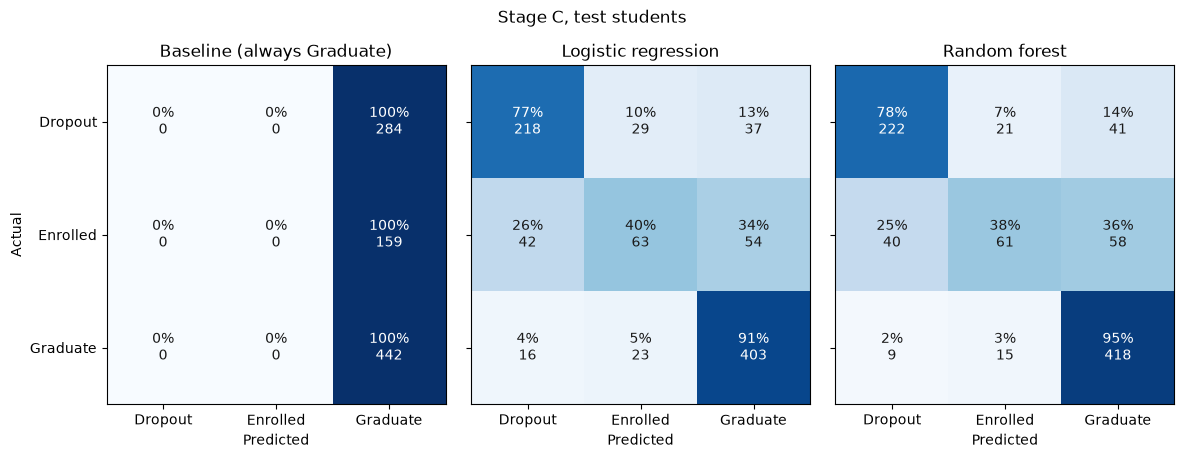

Baseline (always Graduate)
              precision    recall  f1-score   support

     Dropout       0.00      0.00      0.00       284
    Enrolled       0.00      0.00      0.00       159
    Graduate       0.50      1.00      0.67       442

    accuracy                           0.50       885
   macro avg       0.17      0.33      0.22       885
weighted avg       0.25      0.50      0.33       885

Logistic regression
              precision    recall  f1-score   support

     Dropout       0.79      0.77      0.78       284
    Enrolled       0.55      0.40      0.46       159
    Graduate       0.82      0.91      0.86       442

    accuracy                           0.77       885
   macro avg       0.72      0.69      0.70       885
weighted avg       0.76      0.77      0.76       885

Random forest
              precision    recall  f1-score   support

     Dropout       0.82      0.78      0.80       284
    Enrolled       0.63      0.38      0.48       159
    Graduate  

In [42]:
CLASSES = ["Dropout", "Enrolled", "Graduate"]
BASELINE_NAME = "Baseline (always Graduate)"
stage_c_predictions = {
    BASELINE_NAME: baseline.predict(X_test),
    "Logistic regression": stage_models[("Logistic regression", "C")].predict(X_test[STAGE_C]),
    "Random forest": stage_models[("Random forest", "C")].predict(X_test[STAGE_C]),
}
same = int((stage_c_predictions["Logistic regression"] == predicted).sum())
print(f"logistic regression labels that match section 7.2: {same} of {len(predicted)}")

fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), sharey=True)
for ax, (name, guesses) in zip(axes, stage_c_predictions.items()):
    matrix = confusion_matrix(y_test, guesses, labels=CLASSES)
    shares = matrix / matrix.sum(axis=1, keepdims=True) * 100
    ax.imshow(shares, cmap="Blues", vmin=0, vmax=100)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(
                j,
                i,
                f"{shares[i, j]:.0f}%\n{matrix[i, j]}",
                ha="center",
                va="center",
                fontsize=10,
                color="white" if shares[i, j] >= 55 else "#1A1A1A",
            )
    ax.set_xticks(range(len(CLASSES)), CLASSES)
    ax.set_yticks(range(len(CLASSES)), CLASSES)
    ax.set_xlabel("Predicted")
    ax.set_title(name)
axes[0].set_ylabel("Actual")
fig.suptitle("Stage C, test students", y=1.02)
fig.tight_layout()
plt.show()

for name, guesses in stage_c_predictions.items():
    print(name)
    print(classification_report(y_test, guesses, digits=2, zero_division=0))

The baseline puts all 885 students in Graduate. It is right for half of them and finds no dropouts, which is why accuracy alone is not enough here.

The two models make the same kinds of mistake. Both find roughly three quarters or more of the dropouts and over 90% of the graduates. Both get only about 4 in 10 of the students still enrolled, and split the rest between Graduate and Dropout. The worst mistake for an advisor is a student who dropped out and was labelled Graduate, because nobody would look at that record. That cell holds 13% to 14% of the dropouts for both models, about one in seven.

### 7.4 ROC curves

A ROC curve needs a yes/no question, and there are three outcomes, so each panel asks one: is this student a dropout or not, still enrolled or not, a graduate or not (one-vs-rest). The curve uses the predicted chance instead of the final label. Moving along it lowers the cut-off for saying yes, which finds more of the true cases at the price of more false alarms. The area under the curve (AUC) is the chance that a true case is ranked above a student who is not one. The baseline gives every student the same chance, so it is the diagonal, with an AUC of 0.50.

The curves are for stage C. The table gives the AUC for every feature set.

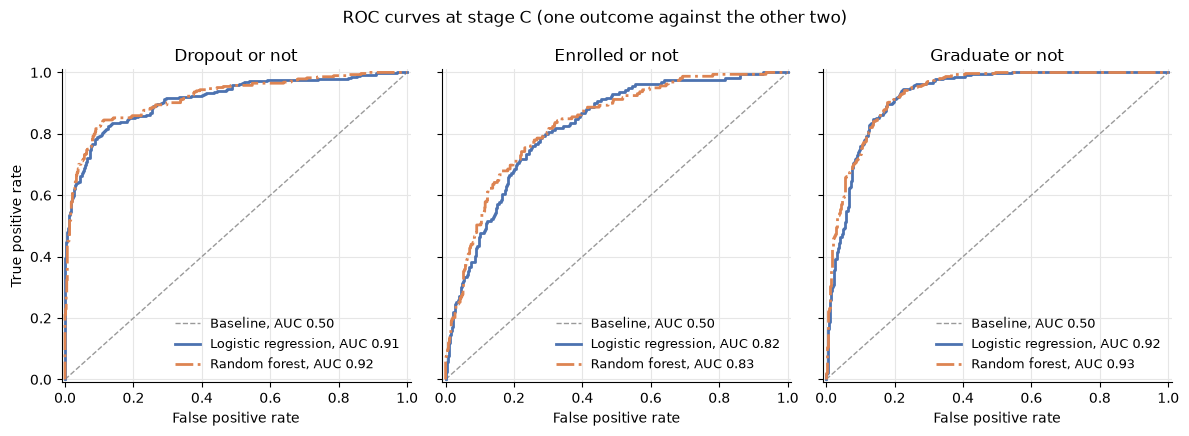

,model,features,AUC Dropout,AUC Enrolled,AUC Graduate,mean AUC
0,Baseline (always Graduate),any,0.500,0.500,0.500,0.500
1,Logistic regression,A (restricted),0.740,0.667,0.715,0.707
2,Logistic regression,A (full),0.808,0.688,0.775,0.757
3,Logistic regression,B,0.903,0.789,0.904,0.865
4,Logistic regression,C,0.913,0.821,0.925,0.886
5,Random forest,A (restricted),0.727,0.645,0.722,0.698
6,Random forest,A (full),0.807,0.690,0.789,0.762
7,Random forest,B,0.897,0.789,0.914,0.867
8,Random forest,C,0.917,0.831,0.932,0.894


In [43]:
def outcome_chances(model_name, set_name):
    """Predicted chance of each outcome for the test students."""
    if model_name == BASELINE_NAME:
        fitted, columns = baseline, list(X_test.columns)
    else:
        fitted, columns = stage_models[(model_name, set_name)], FEATURE_SETS[set_name]
    return pd.DataFrame(
        fitted.predict_proba(X_test[columns]), columns=fitted.classes_, index=X_test.index
    )


curve_styles = {
    BASELINE_NAME: ("#9A9A9A", "--"),
    "Logistic regression": ("#4C72B0", "-"),
    "Random forest": ("#DD8452", "-."),
}
fig, axes = plt.subplots(1, 3, figsize=(12, 4.4), sharey=True)
for ax, outcome in zip(axes, CLASSES):
    is_outcome = (y_test == outcome).to_numpy()
    for name, (color, style) in curve_styles.items():
        chance = outcome_chances(name, "C")[outcome]
        false_positive, true_positive, _ = roc_curve(is_outcome, chance)
        auc = roc_auc_score(is_outcome, chance)
        ax.plot(
            false_positive,
            true_positive,
            color=color,
            linestyle=style,
            linewidth=1 if name == BASELINE_NAME else 2,
            label=f"{name.split(' (')[0]}, AUC {auc:.2f}",
        )
    ax.set_title(f"{outcome} or not")
    ax.set_xlabel("False positive rate")
    ax.set_xlim(-0.01, 1.01)
    ax.set_ylim(-0.01, 1.01)
    ax.grid(color="#E6E6E6", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(loc="lower right", frameon=False, fontsize=9)
axes[0].set_ylabel("True positive rate")
fig.suptitle("ROC curves at stage C (one outcome against the other two)")
fig.tight_layout()
plt.show()

auc_rows = []
for model_name, set_name in [(BASELINE_NAME, "any"), *stage_models]:
    chances = outcome_chances(model_name, set_name)
    row = {"model": model_name, "features": set_name}
    for outcome in CLASSES:
        row[f"AUC {outcome}"] = roc_auc_score((y_test == outcome).to_numpy(), chances[outcome])
    row["mean AUC"] = np.mean([row[f"AUC {outcome}"] for outcome in CLASSES])
    auc_rows.append(row)
auc_results = pd.DataFrame(auc_rows)
display(auc_results.round(3))

At stage C both models rank dropouts and graduates well, with AUCs above 0.90. Enrolled is lower, at a little over 0.80. That is still far above the baseline, so the models do see something about these students. The low recall in 7.2 comes from the final label: Enrolled is the smallest group, and it is rarely the single most likely outcome.

The two curves almost lie on top of each other, so the ROC curves do not separate the two models either. Across the stages, the dropout AUC is about 0.73 to 0.74 on A (restricted), 0.81 on A (full), 0.90 on B, and 0.91 to 0.92 on C. The first semester again adds much more than the second.

### 7.5 Training set size

Would more students help, and are the models underfitting or overfitting? Cross-validation put the logistic regression ahead at stage C, so it is the chosen model. The random forest is shown next to it, because the two behave very differently. Each model keeps the settings chosen in 6.4 and is fit on growing parts of the training rows. Both lines are macro F1, the score used to choose the settings. The dashed line is the score on the rows the model was fit on. The solid line is the score on the held-out fold, averaged over the same 5 folds, with a band of one standard deviation across them. The test rows are not used here.

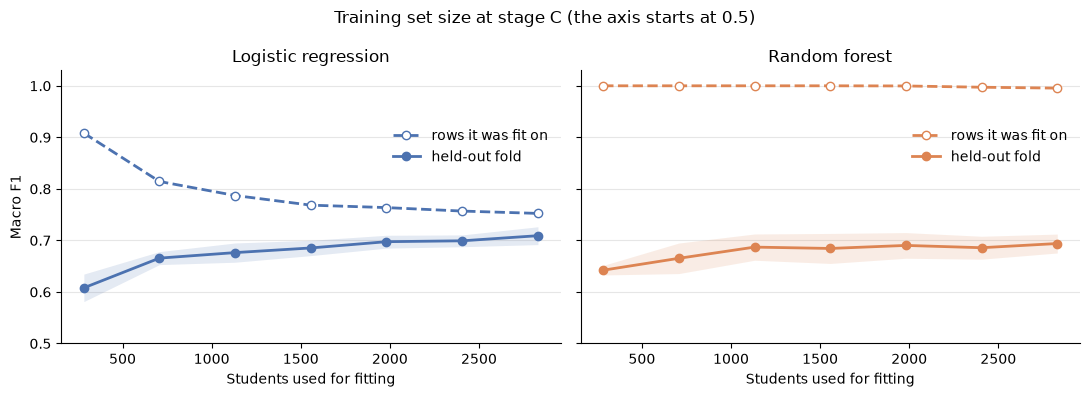

Logistic regression
 students  score on fitted rows  score on held-out fold  held-out std
      283                 0.908                   0.608         0.027
      707                 0.814                   0.666         0.013
     1132                 0.787                   0.676         0.019
     1557                 0.768                   0.685         0.015
     1981                 0.764                   0.698         0.012
     2406                 0.757                   0.699         0.011
     2831                 0.752                   0.709         0.017
Random forest
 students  score on fitted rows  score on held-out fold  held-out std
      283                 1.000                   0.642         0.009
      707                 1.000                   0.665         0.030
     1132                 1.000                   0.687         0.025
     1557                 1.000                   0.684         0.029
     1981                 1.000                   0.690 

In [44]:
size_results = {}
for model_name in MODELS:
    sizes, fit_scores, held_out_scores = learning_curve(
        stage_models[(model_name, "C")],
        X_train[STAGE_C],
        y_train,
        train_sizes=np.linspace(0.1, 1.0, 7),
        cv=cv,
        scoring="f1_macro",
        shuffle=True,
        random_state=RANDOM_SEED,
    )
    size_results[model_name] = pd.DataFrame(
        {
            "students": sizes,
            "score on fitted rows": fit_scores.mean(axis=1),
            "score on held-out fold": held_out_scores.mean(axis=1),
            "held-out std": held_out_scores.std(axis=1),
        }
    )

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (model_name, table) in zip(axes, size_results.items()):
    color = model_styles[model_name][0]
    ax.plot(
        table["students"],
        table["score on fitted rows"],
        color=color,
        linestyle="--",
        marker="o",
        markerfacecolor="white",
        linewidth=2,
        label="rows it was fit on",
    )
    ax.plot(
        table["students"],
        table["score on held-out fold"],
        color=color,
        marker="o",
        linewidth=2,
        label="held-out fold",
    )
    ax.fill_between(
        table["students"],
        table["score on held-out fold"] - table["held-out std"],
        table["score on held-out fold"] + table["held-out std"],
        color=color,
        alpha=0.15,
        linewidth=0,
    )
    ax.set_title(model_name)
    ax.set_xlabel("Students used for fitting")
    ax.set_ylim(0.5, 1.03)
    ax.grid(axis="y", color="#E6E6E6", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(frameon=False, loc="center right", bbox_to_anchor=(1.0, 0.72))
axes[0].set_ylabel("Macro F1")
fig.suptitle("Training set size at stage C (the axis starts at 0.5)")
fig.tight_layout()
plt.show()

for model_name, table in size_results.items():
    print(model_name)
    print(table.round(3).to_string(index=False))

**Logistic regression.** With few students it fits them closely and does worse on the held-out fold. As students are added the two lines move together, ending about 0.04 apart (0.75 against 0.71). A small gap with neither score high points to bias more than variance: the model is too simple, or the fields do not hold enough information, to do much better. The held-out line is still rising slowly at the end, so more students may help a little.

**Random forest.** It scores close to 1.0 on the rows it was fit on at every size, and about 0.69 on the held-out fold. That wide gap is overfitting, or high variance: it nearly memorizes the training rows. Its held-out line is flat from about 1,100 students onward. Section 7.8 shows that it still does about as well as the logistic regression on new students, so the gap describes how it fits and does not by itself make it worse.

This is the expected trade-off between a simple and a flexible model. Both stop near the same held-out score, which suggests that the limit is in the recorded fields more than in the choice of model.

### 7.6 Cost of mistakes

We assign illustrative costs to different errors. For example, predicting Graduate for a student who later drops out may miss an opportunity to offer support. A correct label costs 0.

| Actual | Predicted | Cost | Why |
|---|---|---|---|
| Dropout | Graduate | 5 | the student is missed completely, and no support is offered |
| Dropout | Enrolled | 2 | the student is not flagged, but is at least not marked as on track |
| Enrolled | Graduate | 2 | a delay is missed |
| Enrolled | Dropout | 1 | support is offered to a student who may still benefit |
| Graduate | Dropout | 1 | support is offered to a student who did not need it |
| Graduate | Enrolled | 1 | the same, with a milder label |

The costs are assumptions. We set them after scoring the models and use them only for this sensitivity analysis. The table therefore repeats the result with the first cost at 2, 3, 5, and 10. The score is the average cost per test student, so lower is better.

In [45]:
MISSED_DROPOUT_COSTS = [2, 3, 5, 10]


def cost_table(missed_dropout):
    """Rows are the actual outcome and columns the predicted one."""
    return pd.DataFrame(
        {"Dropout": [0, 1, 1], "Enrolled": [2, 0, 1], "Graduate": [missed_dropout, 2, 0]},
        index=CLASSES,
    )


def average_cost(actual, guesses, costs):
    matrix = confusion_matrix(actual, guesses, labels=CLASSES)
    return (matrix * costs.to_numpy()).sum() / matrix.sum()


display(cost_table(5).rename_axis(index="actual", columns="predicted"))

all_predictions = {(BASELINE_NAME, "any"): baseline.predict(X_test)}
for (model_name, set_name), fitted in stage_models.items():
    all_predictions[(model_name, set_name)] = fitted.predict(X_test[FEATURE_SETS[set_name]])

cost_results = pd.DataFrame(
    {
        f"missed dropout = {cost}": {
            key: average_cost(y_test, guesses, cost_table(cost))
            for key, guesses in all_predictions.items()
        }
        for cost in MISSED_DROPOUT_COSTS
    }
).rename_axis(index=["model", "features"])
display(cost_results.round(3))

predicted,Dropout,Enrolled,Graduate
actual,,,
Dropout,0,2,5
Enrolled,1,0,2
Graduate,1,1,0


missed dropout = 2  \
model                      features                             
Baseline (always Graduate) any                          1.001   
Logistic regression        A (restricted)               0.689   
                           A (full)                     0.617   
                           B                            0.408   
                           C                            0.363   
Random forest              A (restricted)               0.678   
                           A (full)                     0.597   
                           B                            0.412   
                           C                            0.344   

                                           missed dropout = 3  \
model                      features                             
Baseline (always Graduate) any                          1.322   
Logistic regression        A (restricted)               0.827   
                           A (full)                     0.720   
                           B                            0.456   
                           C                            0.405   
Random forest              A (restricted)               0.815   
                           A (full)                     0.707   
                           B                            0.469   
                           C                            0.390   

                                           missed dropout = 5  \
model                      features                             
Baseline (always Graduate) any                          1.964   
Logistic regression        A (restricted)               1.103   
                           A (full)                     0.925   
                           B                            0.554   
                           C                            0.488   
Random forest              A (restricted)               1.088   
                           A (full)                     0.929   
                           B                            0.582   
                           C                            0.482   

                                           missed dropout = 10  
model                      features                             
Baseline (always Graduate) any                           3.568  
Logistic regression        A (restricted)                1.792  
                           A (full)                      1.440  
                           B                             0.797  
                           C                             0.697  
Random forest              A (restricted)                1.772  
                           A (full)                      1.482  
                           B                             0.864  
                           C                             0.714

Average cost fell with each stage for both models under all four sets of weights. When predicting Graduate for a student who dropped out costs 5, average cost per test student is about 1.96 for the baseline, 0.93 for A (full), 0.55–0.58 for B, and 0.48–0.49 for C.

At Stage C, the random forest has a slightly lower average cost when that error costs 2, 3, or 5. Logistic regression has a slightly lower cost when it costs 10. The preferred model under this criterion depends on the assumed costs.

### 7.7 Error analysis

This section looks at which students are mislabelled and what their records have in common. It uses the chosen model, the stage C logistic regression, on the 885 test students. Nothing here is used to change a model.

#### What the mistakes look like

Each row is one combination of actual and predicted outcome. The middle columns are medians for those students, and the last three are the share of them with that mark.

In [46]:
error_predictions = pd.Series(stage_c_predictions["Logistic regression"], index=X_test.index)
error_chances = outcome_chances("Logistic regression", "C")
wrong = error_predictions != y_test
print(f"mislabelled: {int(wrong.sum())} of {len(y_test)} ({wrong.mean() * 100:.1f}%)")

pairs = X_test.assign(actual=y_test, predicted=error_predictions).groupby(["actual", "predicted"])
error_pairs = pd.DataFrame(
    {
        "students": pairs.size(),
        "pass rate 1st sem": pairs["Pass rate 1st sem"].median(),
        "pass rate 2nd sem": pairs["Pass rate 2nd sem"].median(),
        "age": pairs["Age at enrollment"].median(),
        "fees up to date": pairs["Tuition fees up to date"].mean(),
        "scholarship": pairs["Scholarship holder"].mean(),
        "units missing": pairs["Curricular units missing"].mean(),
    }
)
display(error_pairs.round(2))

missed_dropouts = (y_test == "Dropout") & (error_predictions != "Dropout")
print(f"dropouts not flagged: {int(missed_dropouts.sum())} of {int((y_test == 'Dropout').sum())}")
print(
    "of those, fees up to date:",
    int((X_test.loc[missed_dropouts, "Tuition fees up to date"] == 1).sum()),
)

mislabelled: 201 of 885 (22.7%)


students  pass rate 1st sem  pass rate 2nd sem   age  \
actual   predicted                                                         
Dropout  Dropout         218               0.20               0.00  25.0   
         Enrolled         29               0.60               0.60  21.0   
         Graduate         37               0.93               1.00  20.0   
Enrolled Dropout          42               0.68               0.50  21.0   
         Enrolled         63               0.67               0.67  21.0   
         Graduate         54               0.83               0.87  19.5   
Graduate Dropout          16               0.83               0.73  20.0   
         Enrolled         23               0.83               0.83  19.0   
         Graduate        403               1.00               1.00  19.0   

                    fees up to date  scholarship  units missing  
actual   predicted                                               
Dropout  Dropout               0.57         0.06           0.04  
         Enrolled              1.00         0.00           0.00  
         Graduate              1.00         0.19           0.14  
Enrolled Dropout               0.81         0.10           0.00  
         Enrolled              1.00         0.06           0.02  
         Graduate              1.00         0.33           0.11  
Graduate Dropout               0.75         0.19           0.12  
         Enrolled              1.00         0.04           0.00  
         Graduate              0.99         0.39           0.02

dropouts not flagged: 66 of 284
of those, fees up to date: 66


**The dropouts it misses look like students doing well.** A typical dropout that was flagged passed 20% of their units in the first semester and none in the second. A typical dropout labelled Graduate passed over 90% and then all of them. Every one of the dropouts it missed had fees up to date. On the fields we looked at, these students resemble graduates, and the file does not say why a student left (section 2.4 of the report), so a better model on the same fields may still miss many of them.

**Enrolled sits between the other two.** Students still enrolled who are labelled Graduate passed over 80% of their units, and those labelled Dropout passed about two thirds and then half. Their pass rates overlap with those of graduates and students who dropped out. The label may also mix students who finish later with students who never will, since the file stops at the end of the normal program length.

#### How sure the model was

If the chances are useful, the model should be wrong mostly when it is unsure. Each student is grouped by the chance the model gave to the label it picked.

In [47]:
sureness = error_chances.max(axis=1)
bands = pd.cut(sureness, [0, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
sure_table = pd.DataFrame(
    {
        "students": sureness.groupby(bands, observed=True).size(),
        "average chance given": sureness.groupby(bands, observed=True).mean(),
        "share correct": (~wrong).groupby(bands, observed=True).mean(),
    }
).rename_axis("chance of the chosen label")
display(sure_table.round(2))
low = sureness <= 0.6
high = sureness > 0.9
print(f"chance up to 0.6: {int(low.sum())} students, {(~wrong)[low].mean() * 100:.0f}% correct")
print(f"chance above 0.9: {int(high.sum())} students, {(~wrong)[high].mean() * 100:.0f}% correct")

,students,average chance given,share correct
chance of the chosen label,,,
"(0.0, 0.5]",74,0.46,0.45
"(0.5, 0.6]",113,0.55,0.54
"(0.6, 0.7]",104,0.65,0.62
"(0.7, 0.8]",103,0.76,0.78
"(0.8, 0.9]",138,0.86,0.83
"(0.9, 1.0]",353,0.96,0.94


chance up to 0.6: 187 students, 50% correct
chance above 0.9: 353 students, 94% correct


It is. The share correct rises in every band and stays close to the chance the model gave. Above 0.9 it is right more than 9 times in 10, and up to 0.6 it is right about half the time. An advisor should therefore see the chance and not only the label, and treat a low chance as "not sure".

#### Groups of students

Section 1 of the report asks whether results differ across groups. For each group, the left panel is the share of its dropouts that were flagged (dropout recall), and the right panel is the share of its other students who were flagged by mistake (false alarm rate). The lines are 95% intervals (Wilson), which are wide for small groups. The dotted line is all test students. The groups overlap, so a student can be in several of them.

,students,mislabelled,dropouts,flagged,dropout recall,not dropouts,false alarms,false alarm rate
group,,,,,,,,
All test students,885,0.23,284,218,0.77,601,58,0.10
Female,570,0.21,139,104,0.75,431,34,0.08
Male,315,0.25,145,114,0.79,170,24,0.14
Age 20 or under,490,0.25,107,70,0.65,383,29,0.08
Age 21 to 29,256,0.22,102,81,0.79,154,20,0.13
Age 30 or over,139,0.17,75,67,0.89,64,9,0.14
Scholarship,205,0.16,19,12,0.63,186,7,0.04
No scholarship,680,0.25,265,206,0.78,415,51,0.12
Fees up to date,776,0.24,191,125,0.65,585,46,0.08


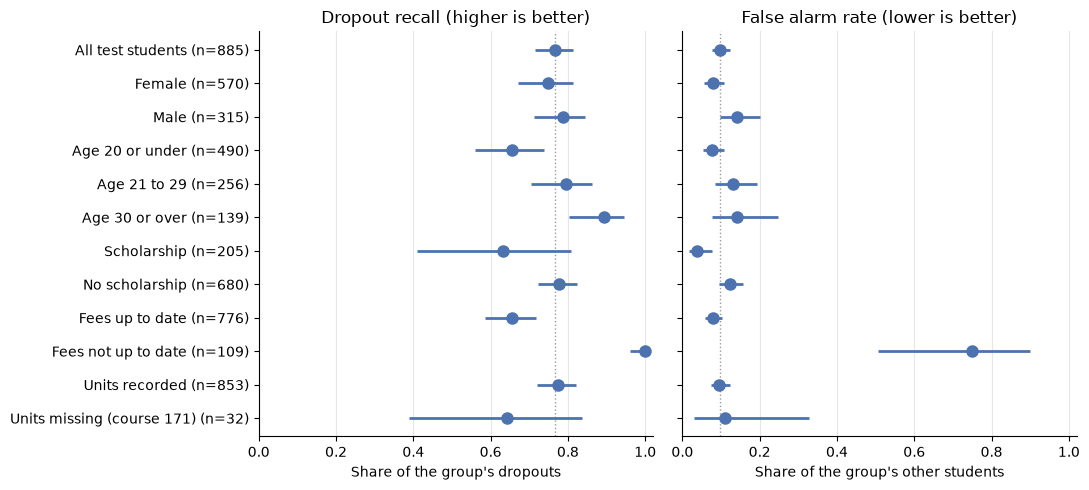

the two fee groups at stage B:
                     dropouts  flagged  not dropouts  false alarms
group                                                             
Fees up to date           191      118           585            45
Fees not up to date        93       92            16            14


In [48]:
def wilson(successes, total, z=1.96):
    """95% interval for a share, which behaves sensibly for small groups."""
    share = successes / total
    centre = (share + z**2 / (2 * total)) / (1 + z**2 / total)
    half = z * np.sqrt(share * (1 - share) / total + z**2 / (4 * total**2)) / (1 + z**2 / total)
    return centre - half, centre + half


GROUPS = {
    "All test students": X_test["Gender"].notna(),
    "Female": X_test["Gender"] == 0,
    "Male": X_test["Gender"] == 1,
    "Age 20 or under": X_test["Age at enrollment"] <= 20,
    "Age 21 to 29": X_test["Age at enrollment"].between(21, 29),
    "Age 30 or over": X_test["Age at enrollment"] >= 30,
    "Scholarship": X_test["Scholarship holder"] == 1,
    "No scholarship": X_test["Scholarship holder"] == 0,
    "Fees up to date": X_test["Tuition fees up to date"] == 1,
    "Fees not up to date": X_test["Tuition fees up to date"] == 0,
    "Units recorded": X_test["Curricular units missing"] == 0,
    "Units missing (course 171)": X_test["Curricular units missing"] == 1,
}


def group_scores(guesses):
    rows = []
    for name, members in GROUPS.items():
        actual, said = y_test[members], guesses[members]
        dropped = actual == "Dropout"
        flagged = said == "Dropout"
        caught, dropouts = int((dropped & flagged).sum()), int(dropped.sum())
        alarms, others = int((~dropped & flagged).sum()), int((~dropped).sum())
        rows.append(
            {
                "group": name,
                "students": len(actual),
                "mislabelled": (actual != said).mean(),
                "dropouts": dropouts,
                "flagged": caught,
                "dropout recall": caught / dropouts,
                "recall interval": wilson(caught, dropouts),
                "not dropouts": others,
                "false alarms": alarms,
                "false alarm rate": alarms / others,
                "alarm interval": wilson(alarms, others),
            }
        )
    return pd.DataFrame(rows).set_index("group")


group_results = group_scores(error_predictions)
display(group_results.drop(columns=["recall interval", "alarm interval"]).round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
panels = [
    ("dropout recall", "recall interval", "Dropout recall (higher is better)", "Share of the group's dropouts"),
    ("false alarm rate", "alarm interval", "False alarm rate (lower is better)", "Share of the group's other students"),
]
y_positions = np.arange(len(group_results))
for ax, (column, interval, title, axis_label) in zip(axes, panels):
    ends = np.array(group_results[interval].tolist())
    ax.axvline(group_results[column].iloc[0], color="#9A9A9A", linestyle=":", linewidth=1)
    ax.hlines(y_positions, ends[:, 0], ends[:, 1], color="#4C72B0", linewidth=2)
    ax.plot(group_results[column], y_positions, "o", color="#4C72B0", markersize=8)
    ax.set_title(title)
    ax.set_xlabel(axis_label)
    ax.set_xlim(0, 1.02)
    ax.grid(axis="x", color="#E6E6E6", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[0].set_yticks(
    y_positions, [f"{name} (n={int(n)})" for name, n in group_results["students"].items()]
)
axes[0].invert_yaxis()
fig.tight_layout()
plt.show()

stage_b_groups = group_scores(
    pd.Series(all_predictions[("Logistic regression", "B")], index=X_test.index)
)
print("the two fee groups at stage B:")
print(
    stage_b_groups.loc[
        ["Fees up to date", "Fees not up to date"],
        ["dropouts", "flagged", "not dropouts", "false alarms"],
    ].to_string()
)

**Fees decide a lot.** Every dropout whose fees are not up to date is flagged, but so are 12 of the 16 students in that group who did not drop out. Among students whose fees are up to date, only about 65% of dropouts are flagged. Stage B, where an advisor would act, shows the same pattern. The difference in false alarms warrants further investigation, particularly because fee status may have been recorded after enrolment (Section 5.3).

**Younger students are missed more often.** Recall is about 65% for students aged 20 or under and about 89% for those aged 30 or over, and the intervals do not overlap. Older students drop out more often in this data, which may be why the model flags them more readily.

**Gender.** Recall is similar for male and female students. Among students who did not drop out, male students were wrongly flagged more often, about 14% against 8%. The two intervals overlap slightly and many groups are compared here, so this is a warning sign to check on more data and not a firm result. Male students do drop out more often in this file (section 4.3), which the model may be picking up.

**Course 171.** About 4 in 10 of the students with no unit counts are mislabelled, against about 2 in 10 of the others. The fill from section 5.2 lets the model run, but it cannot replace what was not recorded. With 32 students this is only a rough figure. Scholarship holders include just 19 dropouts, so their recall is rough too.

#### Courses

Only courses with at least 30 test students are shown, and even these are small.

In [49]:
by_course = pd.DataFrame(
    {
        "students": wrong.groupby(X_test["Course"]).size(),
        "mislabelled": wrong.groupby(X_test["Course"]).mean(),
        "share enrolled": (y_test == "Enrolled").groupby(X_test["Course"]).mean(),
    }
)
by_course.index = [course_names[code] for code in by_course.index]
shown_courses = by_course[by_course["students"] >= 30].sort_values("mislabelled", ascending=False)
display(shown_courses.round(2))
print(f"courses left out (fewer than 30 test students): {int((by_course['students'] < 30).sum())}")

,students,mislabelled,share enrolled
Basic Education,34,0.41,0.38
Animation and Multimedia Design,40,0.40,0.25
Informatics Engineering,37,0.30,0.30
Communication Design,52,0.27,0.19
Veterinary Nursing,60,0.25,0.20
Management,78,0.24,0.22
Management (evening),51,0.24,0.24
Social Service,64,0.23,0.19
Tourism,54,0.22,0.17
Journalism and Communication,64,0.20,0.08


courses left out (fewer than 30 test students): 3


The error is not spread evenly. Basic Education and Animation and Multimedia Design are mislabelled about 4 times in 10, and Social Service (evening) about 1 time in 17. Animation is the course with the missing unit counts. Basic Education has the largest share of students still enrolled, which is the outcome the model finds hardest. With 30 to 60 students in most courses, small differences between courses should not be read as real.

### 7.8 What the evaluation says

A gap between two scores can come from which 885 students happened to be in the test set. The check below draws the test students again with replacement 2,000 times and scores both sides of each comparison on the same draw (a paired bootstrap). If the 95% interval of the gap includes 0, the test set cannot tell the two apart. The interval does not cover the luck of the training rows, so it is on the narrow side.

In [50]:
N_DRAWS = 2000
actual_values = y_test.to_numpy()
draws = np.random.default_rng(RANDOM_SEED).integers(
    0, len(actual_values), (N_DRAWS, len(actual_values))
)


def macro_f1(actual, guesses):
    return f1_score(actual, guesses, average="macro")


def dropout_recall(actual, guesses):
    return (guesses[actual == "Dropout"] == "Dropout").mean()


LR, RF = "Logistic regression", "Random forest"
COMPARISONS = [
    ("random forest minus logistic regression, B", (RF, "B"), (LR, "B")),
    ("random forest minus logistic regression, C", (RF, "C"), (LR, "C")),
    ("logistic regression: A (full) minus A (restricted)", (LR, "A (full)"), (LR, "A (restricted)")),
    ("logistic regression: B minus A (full)", (LR, "B"), (LR, "A (full)")),
    ("logistic regression: C minus B", (LR, "C"), (LR, "B")),
    ("random forest: A (full) minus A (restricted)", (RF, "A (full)"), (RF, "A (restricted)")),
    ("random forest: B minus A (full)", (RF, "B"), (RF, "A (full)")),
    ("random forest: C minus B", (RF, "C"), (RF, "B")),
]
drawn_scores = {}
for key, guesses in all_predictions.items():
    if key[0] == BASELINE_NAME:
        continue
    for label, scorer in (("macro F1", macro_f1), ("dropout recall", dropout_recall)):
        drawn_scores[(key, label)] = np.array(
            [scorer(actual_values[draw], guesses[draw]) for draw in draws]
        )

gap_rows = []
for name, first, second in COMPARISONS:
    row = {"comparison": name}
    for label, scorer in (("macro F1", macro_f1), ("dropout recall", dropout_recall)):
        gap = scorer(actual_values, all_predictions[first]) - scorer(
            actual_values, all_predictions[second]
        )
        low_end, high_end = np.percentile(
            drawn_scores[(first, label)] - drawn_scores[(second, label)], [2.5, 97.5]
        )
        row[f"{label} gap"] = f"{gap:+.3f}"
        row[f"{label} 95% interval"] = f"{low_end:+.3f} to {high_end:+.3f}"
        row[f"{label} includes 0"] = "yes" if low_end <= 0 <= high_end else "no"
    gap_rows.append(row)
gap_results = pd.DataFrame(gap_rows).set_index("comparison")
display(gap_results)

,macro F1 gap,macro F1 95% interval,macro F1 includes 0,dropout recall gap,dropout recall 95% interval,dropout recall includes 0
comparison,,,,,,
"random forest minus logistic regression, B",-0.031,-0.066 to +0.005,yes,+0.007,-0.034 to +0.048,yes
"random forest minus logistic regression, C",+0.016,-0.018 to +0.051,yes,+0.014,-0.022 to +0.050,yes
logistic regression: A (full) minus A (restricted),+0.053,+0.027 to +0.079,no,+0.092,+0.040 to +0.144,no
logistic regression: B minus A (full),+0.151,+0.117 to +0.186,no,+0.151,+0.095 to +0.208,no
logistic regression: C minus B,+0.028,+0.003 to +0.053,no,+0.028,-0.007 to +0.063,yes
random forest: A (full) minus A (restricted),+0.045,+0.012 to +0.078,no,+0.081,+0.022 to +0.137,no
random forest: B minus A (full),+0.126,+0.086 to +0.164,no,+0.141,+0.082 to +0.198,no
random forest: C minus B,+0.075,+0.042 to +0.109,no,+0.035,+0.000 to +0.072,yes


**The question.** Yes, the recorded information predicts the outcome far better than the baseline, though not equally well for all three outcomes. Dropout and Graduate are predicted well and Enrolled is not.

**How early.** The first semester is the largest step for both models, on macro F1 and on dropout recall, and the interval is well away from 0. The second semester does not clearly change dropout recall for either model, since both intervals include 0. It does raise macro F1, by a small amount for the logistic regression and by more for the random forest. So for flagging dropouts, acting after the first semester loses little. For telling all three outcomes apart, the second semester still helps.

**Fees, debt, and scholarship.** At enrolment these three fields add to both measures for both models, and the intervals are above 0. Error rates also differ across fee-status groups in the test set (Section 7.7). The recording dates of these fields are uncertain.

**Which model.** Neither is consistently better. At stages B and C every interval for the gap between them includes 0, the ROC curves overlap, and the cost order depends on the weights. Logistic regression is the preferred model here because it scores higher in cross-validation, has a smaller training-to-validation gap (Section 7.5), and has interpretable coefficients. Under the illustrative cost weights in Section 7.6, either model can have the lower average cost.

**What did not work.** Enrolled stays the weak outcome with both models. Some students who dropped out and were predicted to graduate had strong pass rates and up-to-date fees, illustrating a limit of the recorded predictors.

### 7.9 Feature importance


## 8. Reflection

### 8.1 Key findings and practical implications

### 8.2 Limitations

### 8.3 Ethical and equity considerations

### 8.4 Future work